In [1]:
import pandas as pd
df_collision = pd.read_csv(r"D:\DEPI project\data\processed\dft-road-casualty-statistics-collision-2025-decoded.csv")
df_casualty = pd.read_csv(r"D:\DEPI project\data\processed\dft-road-casualty-statistics-casualty-2025-decoded.csv")
df_vehicle = pd.read_csv(r"D:\DEPI project\data\processed\dft-road-casualty-statistics-vehicle-2025-decoded.csv")

C:\Users\lenovo\AppData\Local\Temp\ipykernel_6732\1435783622.py:4: DtypeWarning: Columns (25: propulsion_code, 27: generic_make_model) have mixed types. Specify dtype option on import or set low_memory=False.
  df_vehicle = pd.read_csv(r"D:\DEPI project\data\processed\dft-road-casualty-statistics-vehicle-2025-decoded.csv")


In [2]:
for name, df in [("casualty", df_casualty), ("collision", df_collision), ("vehicle", df_vehicle)]:
    print(f"The number of columns in {name}: {df.shape[1]}")
    print(df.columns)
    print('-' * 50)

The number of columns in casualty: 24
Index(['collision_index', 'collision_year', 'collision_ref_no',
       'vehicle_reference', 'casualty_reference', 'casualty_class',
       'sex_of_casualty', 'age_of_casualty', 'age_band_of_casualty',
       'casualty_severity', 'pedestrian_location', 'pedestrian_movement',
       'car_passenger', 'bus_or_coach_passenger',
       'pedestrian_road_maintenance_worker', 'casualty_type',
       'casualty_imd_decile', 'lsoa_of_casualty', 'enhanced_casualty_severity',
       'casualty_injury_based', 'casualty_adjusted_severity_serious',
       'casualty_adjusted_severity_slight', 'casualty_distance_banding',
       'escooter_flag'],
      dtype='str')
--------------------------------------------------
The number of columns in collision: 44
Index(['collision_index', 'collision_year', 'collision_ref_no',
       'location_easting_osgr', 'location_northing_osgr', 'longitude',
       'latitude', 'police_force', 'collision_severity', 'number_of_vehicles',
    

In [3]:
casualty_drop = [
    "casualty_severity", "enhanced_casualty_severity", "casualty_adjusted_severity_serious",
    "casualty_adjusted_severity_slight", "casualty_injury_based",
    "collision_year", "collision_ref_no",
    "lsoa_of_casualty", "casualty_imd_decile", "casualty_distance_banding",
    "age_band_of_casualty", "escooter_flag", "bus_or_coach_passenger",
    "pedestrian_road_maintenance_worker",
]

collision_drop = [
    "enhanced_severity_collision", "collision_injury_based",
    "collision_adjusted_severity_serious", "collision_adjusted_severity_slight",
    "number_of_casualties", "collision_year", "collision_ref_no",
    "local_authority_district", "location_easting_osgr", "location_northing_osgr",
    "local_authority_highway_current", "local_authority_highway",
    "junction_detail_historic", "pedestrian_crossing_human_control_historic",
    "pedestrian_crossing_physical_facilities_historic", "carriageway_hazards_historic",
    "special_conditions_at_site", "carriageway_hazards",
    "lsoa_of_accident_location", "first_road_number","second_road_number"
]

vehicle_drop = [
    "vehicle_manoeuvre_historic", "vehicle_location_restricted_lane_historic",
    "journey_purpose_of_driver_historic", "age_band_of_driver",
    "age_of_vehicle", "collision_year", "collision_ref_no",
    "lsoa_of_driver", "driver_imd_decile", "driver_distance_banding",
    "generic_make_model","escooter_flag",
]

In [4]:
df_collision.drop(columns=collision_drop, inplace=True)
df_casualty.drop(columns=casualty_drop, inplace=True)
df_vehicle.drop(columns=vehicle_drop, inplace=True)

for name, df in [("casualty", df_casualty), ("collision", df_collision), ("vehicle", df_vehicle)]:
    print(f"The number of columns in {name} after dropping: {df.shape[1]}")

The number of columns in casualty after dropping: 10
The number of columns in collision after dropping: 23
The number of columns in vehicle after dropping: 20


In [5]:
KEYS = ["collision_index", "vehicle_reference", "casualty_reference"]

UNKNOWN_TOKENS = {
    "-1", "unknown", "not known", "unknown or other",
    "unknown (self reported)", "unknown (self rep only)",
    "unknown vehicle type (self rep only)",
    "not known or not requested",
}

def handle_missing(df):
    df = df.copy()
    for c in df.columns:
        if c in KEYS:
            continue
        if pd.api.types.is_numeric_dtype(df[c]):
            df[c] = df[c].mask(df[c] == -1)
        else:
            norm = df[c].astype("string").str.strip().str.lower()
            df[c] = df[c].mask(norm.isin(UNKNOWN_TOKENS), "Unknown")
    return df

df_collision = handle_missing(df_collision)
df_casualty = handle_missing(df_casualty)
df_vehicle = handle_missing(df_vehicle)

for name, df in [
    ("collision", df_collision),
    ("casualty", df_casualty),
    ("vehicle", df_vehicle)
]:
    print(
        name,
        "| Remaining -1:", df.isin([-1, "-1"]).sum().sum(),
        "| NULL:", df.isna().sum().sum(),
        "| Unknown:", (df == "Unknown").sum().sum()
    )

collision | Remaining -1: 0 | NULL: 4 | Unknown: 76632
casualty | Remaining -1: 0 | NULL: 2741 | Unknown: 9519
vehicle | Remaining -1: 0 | NULL: 73131 | Unknown: 353203


### Cleaned casualty table

In [6]:
def show_categories(df, max_categories=30):
    for c in df.columns:
        if pd.api.types.is_numeric_dtype(df[c]) or c == "collision_index":
            continue

        n = df[c].nunique(dropna=False)

        print("=" * 60)
        print(f"{c} f ({n} categories)")
        counts = df[c].value_counts(dropna=False)

        if n > max_categories:
            print(f"Too many categories ({n}) - showing top 10:")
            print(counts.head(10).to_string())
        else:
            print(counts.to_string())


show_categories(df_casualty)

casualty_class f (3 categories)
casualty_class
Driver or rider    83976
Passenger          23929
Pedestrian         19978
sex_of_casualty f (3 categories)
sex_of_casualty
Male       77637
Female     48874
Unknown     1372
pedestrian_location f (11 categories)
pedestrian_location
Not a Pedestrian                                                           107900
In carriageway, crossing elsewhere                                           7213
Crossing on pedestrian crossing facility                                     3379
On footway or verge                                                          2628
In carriageway, not crossing                                                 2106
Unknown                                                                      1901
In centre of carriageway - not on refuge, island or central reservation      1462
Crossing elsewhere within 50m. of pedestrian crossing                        1078
On refuge, central island or central reservation                

In [7]:
df_casualty.isna().sum()

collision_index           0
vehicle_reference         0
casualty_reference        0
casualty_class            0
sex_of_casualty           0
age_of_casualty        2741
pedestrian_location       0
pedestrian_movement       0
car_passenger             0
casualty_type             0
dtype: int64

In [8]:
CAR_TYPES = {"Car occupant", "Taxi/Private hire car occupant"}
is_car = df_casualty["casualty_type"].isin(CAR_TYPES)
is_car_passenger = is_car & (df_casualty["casualty_class"] == "Passenger")

blank = df_casualty["car_passenger"] == "Unknown"
df_casualty.loc[blank & ~is_car_passenger, "car_passenger"] = "Not car passenger"

print(df_casualty["car_passenger"].value_counts().to_dict())

{'Not car passenger': 106813, 'Front seat passenger': 13257, 'Rear seat passenger': 7698, 'Unknown': 115}


In [9]:
import numpy as np

def group_casualty_type(value: str) -> str:
    """Collapse the 23 casualty_type labels into 10 broader classes."""
    v = str(value).lower()
    if v == "pedestrian":
        return "Pedestrian"
    if v == "cyclist":
        return "Cyclist"
    if v in {"car occupant", "taxi/private hire car occupant"}:
        return "Car or taxi"
    if "motorcycle" in v:
        return "Motorcycle"
    if "powered transporter" in v or "mobility scooter" in v:
        return "E-scooter or mobility scooter"
    if v.startswith("van"):
        return "Light goods (van)"
    if v.startswith("goods vehicle"):
        return "Heavy goods vehicle"
    if v.startswith("bus") or v.startswith("minibus"):
        return "Bus or coach"
    if v == "unknown":
        return "Unknown"
    return "Other"                         # agricultural, horse rider, tram, other

df_casualty["casualty_type"] = df_casualty["casualty_type"].apply(group_casualty_type)
df_casualty["casualty_type"].value_counts()


casualty_type
Car or taxi                      67520
Pedestrian                       19978
Cyclist                          16042
Motorcycle                       15447
Light goods (van)                 3931
Bus or coach                      2269
E-scooter or mobility scooter     1498
Heavy goods vehicle                717
Other                              464
Unknown                             17
Name: count, dtype: int64

In [10]:
df_casualty['age_of_casualty'].describe()

count    125142.000000
mean         38.577168
std          19.748516
min           0.000000
25%          23.000000
50%          35.000000
75%          53.000000
max         105.000000
Name: age_of_casualty, dtype: float64

In [11]:
age_median = df_casualty.groupby("casualty_class")["age_of_casualty"].transform("median")
df_casualty["age_of_casualty"] = df_casualty["age_of_casualty"].fillna(age_median).astype(int)

print(df_casualty.shape)
print("NaN:", df_casualty.isna().sum().sum())

(127883, 10)
NaN: 0


### Cleaned vehicle table

In [12]:
df_vehicle.info()

<class 'pandas.DataFrame'>
RangeIndex: 183948 entries, 0 to 183947
Data columns (total 20 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   collision_index                   183948 non-null  str    
 1   vehicle_reference                 183948 non-null  int64  
 2   vehicle_type                      183948 non-null  str    
 3   towing_and_articulation           183948 non-null  str    
 4   vehicle_manoeuvre                 183948 non-null  str    
 5   vehicle_direction_from            183948 non-null  str    
 6   vehicle_direction_to              183948 non-null  str    
 7   vehicle_location_restricted_lane  183948 non-null  str    
 8   junction_location                 183948 non-null  str    
 9   skidding_and_overturning          183948 non-null  str    
 10  hit_object_in_carriageway         183948 non-null  str    
 11  vehicle_leaving_carriageway       183948 non-null  str    
 12 

In [13]:
show_categories(df_vehicle)

vehicle_type f (22 categories)
vehicle_type
Car                                      123212
Pedal cycle                               17021
Van / Goods 3.5 tonnes mgw or under       12555
Motorcycle 125cc and under                 7876
Motorcycle over 500cc                      4976
Taxi/Private hire car                      3614
Bus or coach (17 or more pass seats)       3023
Goods 7.5 tonnes mgw and over              2633
Motorcycle over 125cc and up to 500cc      1792
Personal powered transporter               1469
Goods over 3.5t. and under 7.5t             884
Motorcycle 50cc and under                   813
Other vehicle                               770
Goods vehicle - unknown weight              673
Motorcycle - unknown cc                     636
Electric motorcycle                         602
Agricultural vehicle                        357
Mobility scooter                            346
Minibus (8 - 16 passenger seats)            296
Unknown                                     

In [14]:
df_vehicle.isnull().sum()

collision_index                         0
vehicle_reference                       0
vehicle_type                            0
towing_and_articulation                 0
vehicle_manoeuvre                       0
vehicle_direction_from                  0
vehicle_direction_to                    0
vehicle_location_restricted_lane        0
junction_location                       0
skidding_and_overturning                0
hit_object_in_carriageway               0
vehicle_leaving_carriageway             0
hit_object_off_carriageway              0
first_point_of_impact                   0
vehicle_left_hand_drive                 0
journey_purpose_of_driver               0
sex_of_driver                           0
age_of_driver                       28262
engine_capacity_cc                  44869
propulsion_code                         0
dtype: int64

In [15]:
NO_ENGINE_TYPES = [
    "Pedal cycle", "Personal powered transporter", "Mobility scooter",
    "Electric motorcycle", "Ridden horse", "Tram",
]

no_engine = df_vehicle["vehicle_type"].isin(NO_ENGINE_TYPES)
to_fill = no_engine & df_vehicle["engine_capacity_cc"].isna()

print("Total rows in no-engine types:", no_engine.sum())
print("Rows to fill with 0:", to_fill.sum())
print(df_vehicle.loc[to_fill, "vehicle_type"].value_counts())
print("Missing engine rows that remain:", (df_vehicle["engine_capacity_cc"].isna() & ~to_fill).sum())

Total rows in no-engine types: 19544
Rows to fill with 0: 19536
vehicle_type
Pedal cycle                     17021
Personal powered transporter     1469
Electric motorcycle               594
Mobility scooter                  346
Ridden horse                       78
Tram                               28
Name: count, dtype: int64
Missing engine rows that remain: 25333


In [16]:
df_vehicle.loc[no_engine & df_vehicle["engine_capacity_cc"].isna(), "engine_capacity_cc"] = 0

engine_median_by_type = df_vehicle.groupby("vehicle_type")["engine_capacity_cc"].median()
global_engine_median = df_vehicle["engine_capacity_cc"].median()

df_vehicle["engine_capacity_cc"] = (
    df_vehicle["engine_capacity_cc"]
    .fillna(df_vehicle["vehicle_type"].map(engine_median_by_type))
    .fillna(global_engine_median)  # fallback if a type has no engine values at all
)

print("Engine NaN left:", df_vehicle["engine_capacity_cc"].isna().sum())

Engine NaN left: 0


In [17]:
def group_vehicle_type(value) -> str:
    v = str(value).lower()
    if v == "unknown":
        return "Unknown"
    if "pedal cycle" in v:
        return "Cyclist"
    if "motorcycle" in v:
        return "Motorcycle"
    if "powered transporter" in v or "mobility scooter" in v:
        return "E-scooter or mobility scooter"
    if "taxi" in v or "private hire" in v or v.startswith("car"):
        return "Car or taxi"
    if "bus" in v or "minibus" in v:
        return "Bus or coach"
    if v.startswith("van"):
        return "Light goods (van)"
    if "over 3.5t" in v or "7.5 tonnes" in v:
        return "Heavy goods vehicle"
    return "Other"

df_vehicle["vehicle_type"] = df_vehicle["vehicle_type"].apply(group_vehicle_type)
print(df_vehicle["vehicle_type"].value_counts())

vehicle_type
Car or taxi                      126826
Cyclist                           17021
Motorcycle                        16695
Light goods (van)                 12555
Heavy goods vehicle                3517
Bus or coach                       3319
Other                              1906
E-scooter or mobility scooter      1815
Unknown                             294
Name: count, dtype: int64


In [18]:
MANOEUVRE_GROUPS = {
    "Going ahead": "Going ahead",
    "Turning right": "Turning",
    "Turning left": "Turning",
    "Waiting to turn right": "Waiting to turn",
    "Waiting to turn left": "Waiting to turn",
    "Slowing or stopping": "Stopped or parked",
    "Waiting to go - held up": "Stopped or parked",
    "Parked": "Stopped or parked",
    "Parking": "Stopped or parked",
    "Moving off": "Moving off",
    "Overtaking moving vehicle - offside": "Overtaking",
    "Overtaking static vehicle - offside": "Overtaking",
    "Overtaking on nearside (passengers side nearest kerb)": "Overtaking",
    "Changing lane to right": "Changing lane",
    "Changing lane to left": "Changing lane",
    "Reversing": "Reversing",
    "U-turn": "U-turn",
    "Unknown": "Unknown",
}

unmapped = df_vehicle.loc[~df_vehicle["vehicle_manoeuvre"].isin(MANOEUVRE_GROUPS), "vehicle_manoeuvre"].unique()
print("Unmapped labels:", unmapped)

df_vehicle["vehicle_manoeuvre"] = df_vehicle["vehicle_manoeuvre"].map(MANOEUVRE_GROUPS)
print(df_vehicle["vehicle_manoeuvre"].value_counts())

Unmapped labels: <StringArray>
[]
Length: 0, dtype: str
vehicle_manoeuvre
Going ahead          93399
Stopped or parked    25417
Turning              22342
Unknown              18281
Moving off            8818
Overtaking            6193
Waiting to turn       3055
Changing lane         3019
Reversing             2217
U-turn                1207
Name: count, dtype: int64


In [19]:
PROPULSION_GROUPS = {
    "Petrol": "Petrol",
    "Heavy oil": "Diesel",
    "Hybrid electric": "Hybrid",
    "Electric diesel": "Hybrid",
    "Electric": "Electric",
    "Gas/Bi-fuel": "Gas",
    "Gas": "Gas",
    "Petrol/Gas (LPG)": "Gas",
    "Gas Diesel": "Other",
    "New fuel technology": "Other",
    "Unknown": "Unknown",
}

unmapped = df_vehicle.loc[~df_vehicle["propulsion_code"].isin(PROPULSION_GROUPS), "propulsion_code"].unique()
print("Unmapped labels:", unmapped)

df_vehicle["propulsion_code"] = df_vehicle["propulsion_code"].map(PROPULSION_GROUPS)
print(df_vehicle["propulsion_code"].value_counts())

Unmapped labels: []
propulsion_code
Petrol      74024
Diesel      50184
Unknown     38869
Hybrid      14666
Electric     6060
Gas           143
Other           2
Name: count, dtype: int64


In [20]:
not_driver = (df_vehicle["age_of_driver"] <=18) | (df_vehicle["age_of_driver"] >= 80)
print("Drivers under 18 or over 80:", not_driver.sum())

Drivers under 18 or over 80: 12610


In [21]:
driver_age_median = df_vehicle.groupby("vehicle_type")["age_of_driver"].transform("median")
global_age_median = df_vehicle["age_of_driver"].median()
df_vehicle["age_of_driver"] = df_vehicle["age_of_driver"].fillna(driver_age_median).fillna(global_age_median).astype(int)
df_vehicle["age_of_driver"] = df_vehicle["age_of_driver"].clip(lower=18, upper=80).astype(int)
print("Driver age NaN left:", df_vehicle["age_of_driver"].isna().sum())

Driver age NaN left: 0


In [22]:
print(df_vehicle.shape)
print("NaN:", df_vehicle.isna().sum().sum())

(183948, 20)
NaN: 0


### Cleaned collision table

In [23]:
df_collision.info()

<class 'pandas.DataFrame'>
RangeIndex: 101525 entries, 0 to 101524
Data columns (total 23 columns):
 #   Column                                       Non-Null Count   Dtype  
---  ------                                       --------------   -----  
 0   collision_index                              101525 non-null  str    
 1   longitude                                    101523 non-null  float64
 2   latitude                                     101523 non-null  float64
 3   police_force                                 101525 non-null  str    
 4   collision_severity                           101525 non-null  str    
 5   number_of_vehicles                           101525 non-null  int64  
 6   date                                         101525 non-null  str    
 7   day_of_week                                  101525 non-null  str    
 8   time                                         101525 non-null  str    
 9   local_authority_ons_district                 101525 non-null  str    


In [24]:
df_collision.isnull().sum()

collision_index                                0
longitude                                      2
latitude                                       2
police_force                                   0
collision_severity                             0
number_of_vehicles                             0
date                                           0
day_of_week                                    0
time                                           0
local_authority_ons_district                   0
first_road_class                               0
road_type                                      0
speed_limit                                    0
junction_detail                                0
junction_control                               0
second_road_class                              0
pedestrian_crossing                            0
light_conditions                               0
weather_conditions                             0
road_surface_conditions                        0
urban_or_rural_area 

In [25]:
show_categories(df_collision)

police_force f (44 categories)
Too many categories (44) - showing top 10:
police_force
Metropolitan Police    20692
West Midlands           4738
Police Scotland         4104
West Yorkshire          3895
Hampshire               3503
Kent                    3417
Sussex                  3252
Thames Valley           3007
Essex                   2877
Devon and Cornwall      2833
collision_severity f (3 categories)
collision_severity
Slight     74881
Serious    25191
Fatal       1453
date f (365 categories)
Too many categories (365) - showing top 10:
date
2025-12-19    412
2025-11-13    402
2025-11-21    397
2025-12-05    396
2025-05-09    389
2025-11-14    387
2025-05-14    385
2025-02-28    385
2025-10-03    383
2025-10-24    383
day_of_week f (7 categories)
day_of_week
Friday       16811
Wednesday    15369
Thursday     15304
Tuesday      14880
Monday       14309
Saturday     13655
Sunday       11197
time f (1440 categories)
Too many categories (1440) - showing top 10:
time
17:00    891
16

In [26]:
df_collision["date"] = pd.to_datetime(df_collision["date"], format="%Y-%m-%d", errors="coerce")
df_collision["time"] = pd.to_datetime(df_collision["time"], format="%H:%M", errors="coerce")

In [27]:
df_collision['hour'] = df_collision['time'].dt.hour
df_collision['month'] = df_collision['date'].dt.month

df_collision['is_weekend'] = df_collision['date'].dt.dayofweek.isin([5, 6]).astype(int)

df_collision.drop(columns=['date', 'time', 'day_of_week','police_force','local_authority_ons_district'], inplace=True)

print(f"Collision table shape after time feature extraction: {df_collision.shape}")

Collision table shape after time feature extraction: (101525, 21)


In [28]:
df_collision.isna().sum()

collision_index                                0
longitude                                      2
latitude                                       2
collision_severity                             0
number_of_vehicles                             0
first_road_class                               0
road_type                                      0
speed_limit                                    0
junction_detail                                0
junction_control                               0
second_road_class                              0
pedestrian_crossing                            0
light_conditions                               0
weather_conditions                             0
road_surface_conditions                        0
urban_or_rural_area                            0
did_police_officer_attend_scene_of_accident    0
trunk_road_flag                                0
hour                                           0
month                                          0
is_weekend          

In [29]:
df_collision = df_collision.dropna(subset=["longitude", "latitude"])

In [30]:
for col in df_collision.select_dtypes(include=["object","str"]).columns:
    print(f"{col}: {(df_collision[col] == 'Unknown').sum()} , {(df_collision[col] == 'Unknown').mean() * 100:.2f}%")

collision_index: 0 , 0.00%
collision_severity: 0 , 0.00%
first_road_class: 5 , 0.00%
road_type: 1952 , 1.92%
junction_detail: 8128 , 8.01%
junction_control: 48013 , 47.29%
second_road_class: 217 , 0.21%
pedestrian_crossing: 6828 , 6.73%
light_conditions: 16 , 0.02%
weather_conditions: 2385 , 2.35%
road_surface_conditions: 1976 , 1.95%
urban_or_rural_area: 0 , 0.00%
did_police_officer_attend_scene_of_accident: 0 , 0.00%
trunk_road_flag: 7106 , 7.00%


In [31]:
df_collision.drop("junction_control", axis=1, inplace=True)

In [32]:
drop_unknown = ["first_road_class","second_road_class","light_conditions"]
print((df_collision[drop_unknown] == 'Unknown').sum())
df_collision = df_collision[~(df_collision[drop_unknown] == 'Unknown').any(axis=1)]

first_road_class       5
second_road_class    217
light_conditions      16
dtype: int64


In [33]:
replace_unknown = ["road_type","junction_detail","pedestrian_crossing","weather_conditions","road_surface_conditions","trunk_road_flag"]
for col in replace_unknown:
    mode = df_collision.loc[
        df_collision[col] != 'Unknown', col
    ].mode()

    if not mode.empty:
        df_collision[col] = df_collision[col].replace(
            'Unknown', mode.iloc[0]
        )

In [34]:
show_categories(df_collision)

collision_severity f (3 categories)
collision_severity
Slight     74676
Serious    25161
Fatal       1448
first_road_class f (6 categories)
first_road_class
A               43713
Unclassified    36856
B               12943
C                4547
Motorway         3029
A(M)              197
road_type f (5 categories)
road_type
Single carriageway    75963
Dual carriageway      14576
Roundabout             6777
One way street         2387
Slip road              1582
junction_detail f (6 categories)
junction_detail
Not at junction or within 20 metres                   53313
T or staggered junction                               28164
Crossroads                                             9450
Other junction                                         6725
Using private drive or entrance                        2133
Junction with more than four arms (not roundabout)     1500
second_road_class f (7 categories)
second_road_class
Unclassified                           56337
Not at junction or within 2

In [35]:
#  urban_or_rural_area: Unallocated (2) -> Urban (66,992)
df_collision['urban_or_rural_area'] = df_collision['urban_or_rural_area'].replace({
    'Unallocated': 'Urban'
})

#  road_surface_conditions: Flood (151) + Wet (22,274) | Snow (146) + Frost/ice (1,259)
df_collision['road_surface_conditions'] = df_collision['road_surface_conditions'].replace({
    'Wet or damp': 'Wet or Flooded',
    'Flood over 3cm. deep': 'Wet or Flooded',
    'Frost or ice': 'Snow or Ice',
    'Snow': 'Snow or Ice'
})

#  weather_conditions: Fine+winds (712) -> Fine | Rain+winds (880) -> Raining | Fog (342) + Snow (250) -> Fog/Snow
df_collision['weather_conditions'] = df_collision['weather_conditions'].replace({
    'Fine no high winds': 'Fine',
    'Fine + high winds': 'Fine',
    'Raining no high winds': 'Raining',
    'Raining + high winds': 'Raining',
    'Fog or mist': 'Fog, Mist or Snow',
    'Snowing no high winds': 'Fog, Mist or Snow',
    'Snowing + high winds': 'Fog, Mist or Snow'
})


# light_conditions: lights unlit (718) + no lighting (5,672)
df_collision['light_conditions'] = df_collision['light_conditions'].replace({
    'Darkness - no lighting': 'Darkness - Unlit or No Lighting',
    'Darkness - lights unlit': 'Darkness - Unlit or No Lighting'
})

#  first_road_class & second_road_class: A(M) (197 & 72) + Motorway (3,029 & 752)
df_collision['first_road_class'] = df_collision['first_road_class'].replace({
    'Motorway': 'Motorway or A(M)',
    'A(M)': 'Motorway or A(M)'
})
df_collision['second_road_class'] = df_collision['second_road_class'].replace({
    'Motorway': 'Motorway or A(M)',
    'A(M)': 'Motorway or A(M)'
})

#  pedestrian_crossing: Human (560 + 253) + Bridge (184) = 997
df_collision['pedestrian_crossing'] = df_collision['pedestrian_crossing'].replace({
    'Human crossing control by other authorised person': 'Human Control or Bridge/Subway',
    'Human crossing control by school crossing patrol': 'Human Control or Bridge/Subway',
    'Footbridge or subway': 'Human Control or Bridge/Subway'
})

In [36]:
df_collision.describe()

,longitude,latitude,number_of_vehicles,speed_limit,hour,month,is_weekend
count,101285.000000,101285.000000,101285.000000,101285.000000,101285.000000,101285.000000,101285.000000
mean,-1.224804,52.376491,1.811877,35.766994,13.728272,6.608856,0.244834
std,1.357449,1.309048,0.689386,14.629334,5.119508,3.421568,0.429991
min,-7.417720,49.912530,1.000000,20.000000,0.000000,1.000000,0.000000
25%,-2.119140,51.464320,1.000000,30.000000,10.000000,4.000000,0.000000
50%,-1.140010,51.889420,2.000000,30.000000,14.000000,7.000000,0.000000
75%,-0.138310,53.327150,2.000000,40.000000,17.000000,10.000000,0.000000
max,1.755590,60.345250,17.000000,70.000000,23.000000,12.000000,1.000000


In [37]:
duplicate_casualties = df_casualty.duplicated(subset=['collision_index', 'casualty_reference']).sum()
print(f"Duplicate casualty keys: {duplicate_casualties}")
df_casualty = df_casualty.drop_duplicates(subset=['collision_index', 'casualty_reference'], keep='first')

duplicate_vehicles = df_vehicle.duplicated(subset=['collision_index', 'vehicle_reference']).sum()
print(f"Duplicate vehicle keys: {duplicate_vehicles}")
df_vehicle = df_vehicle.drop_duplicates(subset=['collision_index', 'vehicle_reference'], keep='first')

# 3. Find intersection (common keys across all three tables)
valid_collisions = (
    set(df_collision['collision_index']) &
    set(df_casualty['collision_index']) &
    set(df_vehicle['collision_index'])
)
print(f"Number of valid common collisions: {len(valid_collisions)}")

df_collision = df_collision[df_collision['collision_index'].isin(valid_collisions)]
df_casualty = df_casualty[df_casualty['collision_index'].isin(valid_collisions)]
df_vehicle = df_vehicle[df_vehicle['collision_index'].isin(valid_collisions)]

print(f"Unique collisions in collision table: {df_collision['collision_index'].nunique()}")
print(f"Unique collisions in casualty table: {df_casualty['collision_index'].nunique()}")
print(f"Unique collisions in vehicle table: {df_vehicle['collision_index'].nunique()}")

Duplicate casualty keys: 0
Duplicate vehicle keys: 0
Number of valid common collisions: 101285
Unique collisions in collision table: 101285
Unique collisions in casualty table: 101285
Unique collisions in vehicle table: 101285


In [38]:
drop_vehicle = ['vehicle_reference']
drop_casualty = ['vehicle_reference', 'casualty_reference']

df_vehicle.drop(columns=drop_vehicle, inplace=True)
df_casualty.drop(columns=drop_casualty, inplace=True)

print( {df_collision.shape})
print({df_vehicle.shape})
print({df_casualty.shape})

{(101285, 20)}
{(183516, 19)}
{(127598, 8)}


In [39]:
veh_agg = df_vehicle.assign(
    has_two_wheeler=df_vehicle['vehicle_type'].isin(['Motorcycle', 'Cyclist', 'E-scooter or mobility scooter']),
    any_overturned=df_vehicle['skidding_and_overturning'].isin(['Overturned', 'Skidded and overturned', 'Jackknifed and overturned']),
    any_left_road=~df_vehicle['vehicle_leaving_carriageway'].isin(['Did not leave carriageway', 'Unknown']),
).groupby('collision_index').agg(
    has_two_wheeler=('has_two_wheeler', 'max'),
    any_overturned=('any_overturned', 'max'),
    any_left_road=('any_left_road', 'max'),
    max_engine_cc=('engine_capacity_cc', 'max'),
)

cas_agg = df_casualty.assign(
    has_pedestrian=df_casualty['casualty_type'].eq('Pedestrian'),
).groupby('collision_index').agg(
    has_pedestrian=('has_pedestrian', 'max'),
    mean_casualty_age=('age_of_casualty', 'mean'),
)

df_final = df_collision.join(veh_agg, on='collision_index').join(cas_agg, on='collision_index')

print("Final shape:", df_final.shape)
print("Remaining NaNs:", df_final.isna().sum().sum())

Final shape: (101285, 26)
Remaining NaNs: 0


In [40]:
df_final = df_final.drop(columns=['collision_index'])

In [41]:
import os
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import loguniform, randint, uniform

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, log_loss, roc_auc_score,
    matthews_corrcoef, confusion_matrix, classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings('ignore')


In [42]:
df=pd.read_csv('D:\DEPI project\data\processed\df_final.csv')

## EDA

In [43]:
df.shape

(101285, 25)

In [44]:
df.head()

,longitude,latitude,collision_severity,number_of_vehicles,first_road_class,road_type,speed_limit,junction_detail,second_road_class,pedestrian_crossing,...,trunk_road_flag,hour,month,is_weekend,has_two_wheeler,any_overturned,any_left_road,max_engine_cc,has_pedestrian,mean_casualty_age
0,-1.26420,54.56650,Slight,1,B,Single carriageway,30,Not at junction or within 20 metres,Not at junction or within 20 metres,Zebra crossing,...,Non-trunk,15,2,0,True,False,False,1745.0,True,11.0
1,-1.15704,54.55967,Slight,2,C,Single carriageway,30,Not at junction or within 20 metres,Not at junction or within 20 metres,No physical crossing facility within 50m,...,Non-trunk,9,5,0,False,False,False,1598.0,False,52.0
2,-2.68516,53.33884,Slight,2,Unclassified,Single carriageway,30,T or staggered junction,Unclassified,Pedestrian phase at traffic signal,...,Non-trunk,18,11,0,False,False,True,1997.0,False,35.5
3,-2.57655,53.43386,Slight,2,C,Single carriageway,40,Not at junction or within 20 metres,Not at junction or within 20 metres,No physical crossing facility within 50m,...,Non-trunk,16,5,0,False,False,False,1995.0,False,31.0
4,-2.51157,53.39967,Slight,7,Motorway or A(M),Dual carriageway,70,Not at junction or within 20 metres,Not at junction or within 20 metres,No physical crossing facility within 50m,...,Trunk (Roads managed by Highways England),7,12,0,False,False,False,2998.0,False,38.0


In [45]:
df.isnull().sum()

longitude                                      0
latitude                                       0
collision_severity                             0
number_of_vehicles                             0
first_road_class                               0
road_type                                      0
speed_limit                                    0
junction_detail                                0
second_road_class                              0
pedestrian_crossing                            0
light_conditions                               0
weather_conditions                             0
road_surface_conditions                        0
urban_or_rural_area                            0
did_police_officer_attend_scene_of_accident    0
trunk_road_flag                                0
hour                                           0
month                                          0
is_weekend                                     0
has_two_wheeler                                0
any_overturned      

In [46]:
df.duplicated().sum()

np.int64(0)

In [47]:
df.describe()

,longitude,latitude,number_of_vehicles,speed_limit,hour,month,is_weekend,max_engine_cc,mean_casualty_age
count,101285.000000,101285.000000,101285.000000,101285.000000,101285.000000,101285.000000,101285.000000,101285.000000,101285.000000
mean,-1.224804,52.376491,1.811877,35.766994,13.728272,6.608856,0.244834,2112.902513,38.752341
std,1.357449,1.309048,0.689386,14.629334,5.119508,3.421568,0.429991,1911.593091,18.675267
min,-7.417720,49.912530,1.000000,20.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,-2.119140,51.464320,1.000000,30.000000,10.000000,4.000000,0.000000,1498.000000,24.000000
50%,-1.140010,51.889420,2.000000,30.000000,14.000000,7.000000,0.000000,1598.000000,36.000000
75%,-0.138310,53.327150,2.000000,40.000000,17.000000,10.000000,0.000000,1997.000000,52.000000
max,1.755590,60.345250,17.000000,70.000000,23.000000,12.000000,1.000000,48000.000000,105.000000


In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101285 entries, 0 to 101284
Data columns (total 25 columns):
 #   Column                                       Non-Null Count   Dtype  
---  ------                                       --------------   -----  
 0   longitude                                    101285 non-null  float64
 1   latitude                                     101285 non-null  float64
 2   collision_severity                           101285 non-null  str    
 3   number_of_vehicles                           101285 non-null  int64  
 4   first_road_class                             101285 non-null  str    
 5   road_type                                    101285 non-null  str    
 6   speed_limit                                  101285 non-null  int64  
 7   junction_detail                              101285 non-null  str    
 8   second_road_class                            101285 non-null  str    
 9   pedestrian_crossing                          101285 non-null  str    


In [49]:
numcols = [
    'longitude',
    'latitude',
    'number_of_vehicles',
    'speed_limit',
    'hour',
    'month',
    'is_weekend',
    'max_engine_cc',
    'mean_casualty_age'
]

catcols = [
    'collision_severity',
    'first_road_class',
    'road_type',
    'junction_detail',
    'second_road_class',
    'pedestrian_crossing',
    'light_conditions',
    'weather_conditions',
    'road_surface_conditions',
    'urban_or_rural_area',
    'did_police_officer_attend_scene_of_accident',
    'trunk_road_flag',
    'has_two_wheeler',
    'any_overturned',
    'any_left_road',
    'has_pedestrian'
]

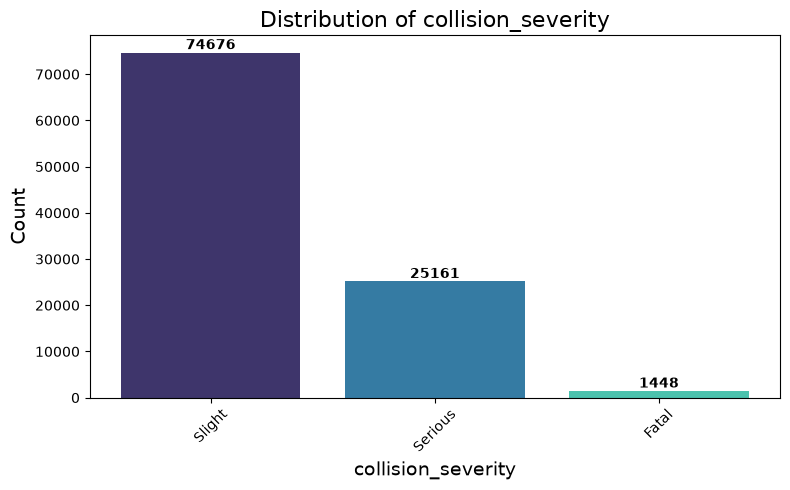

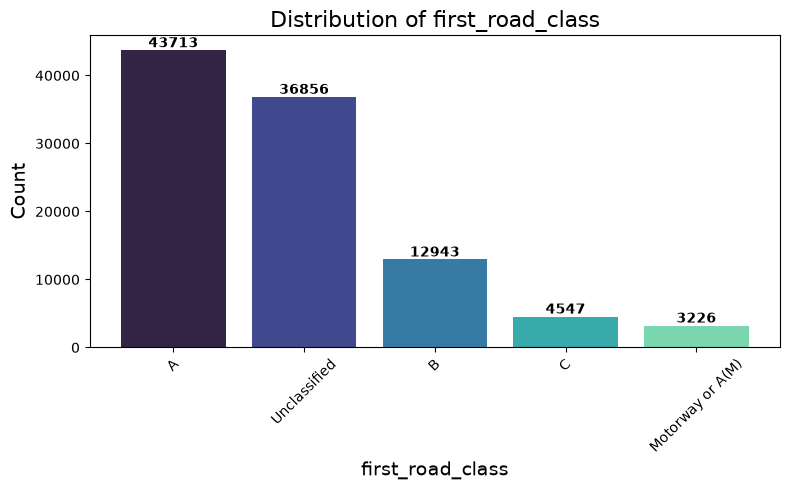

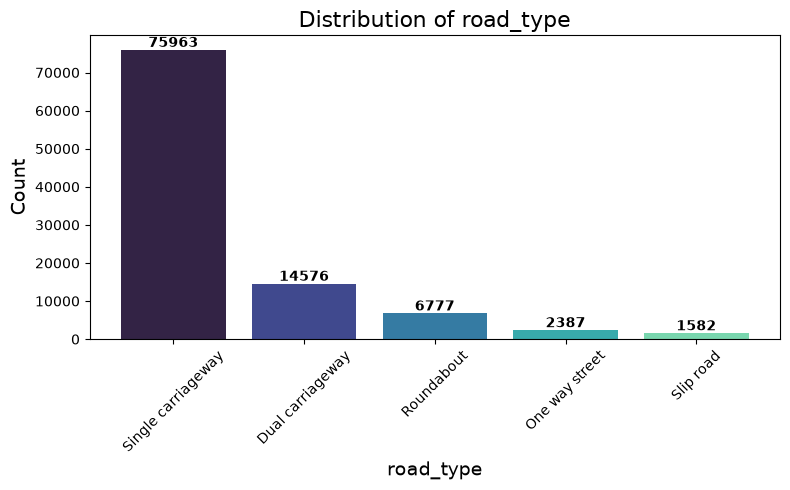

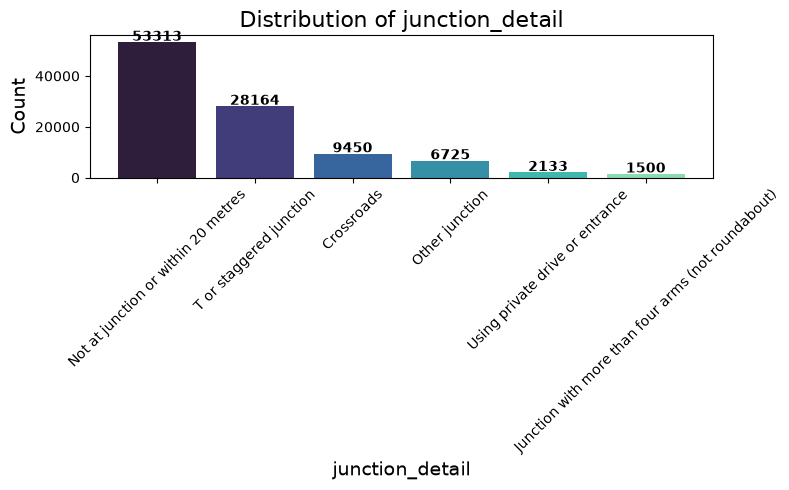

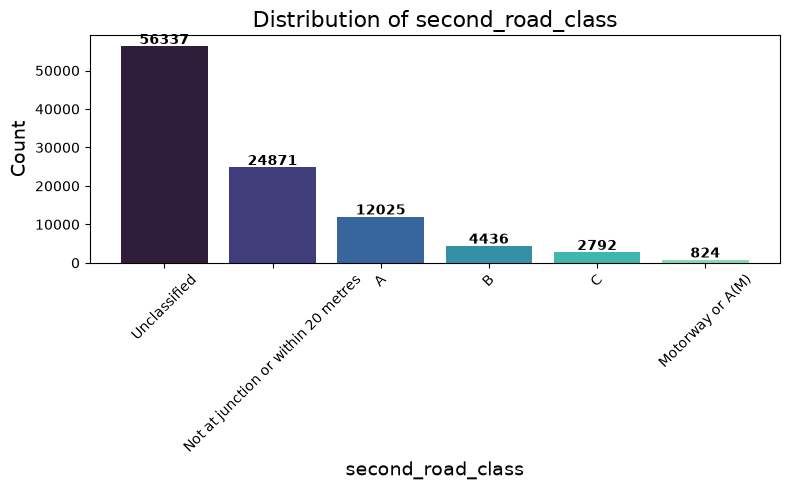

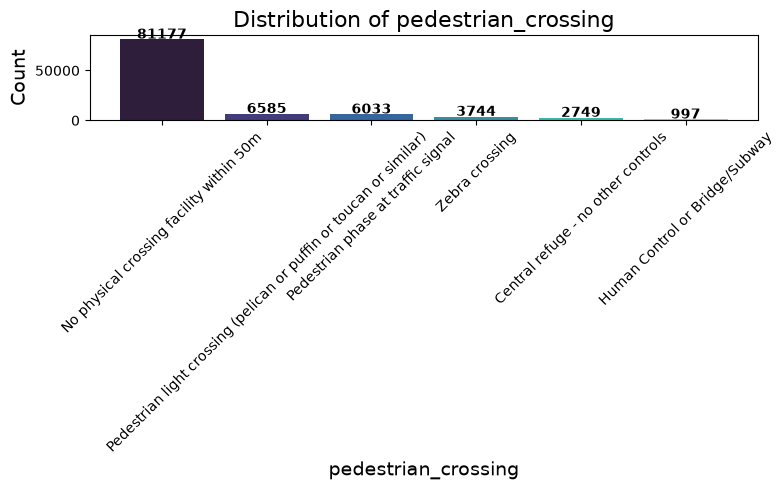

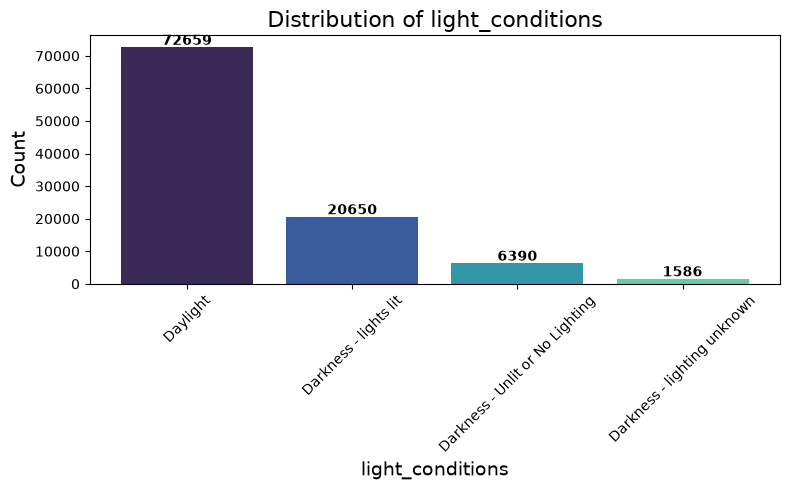

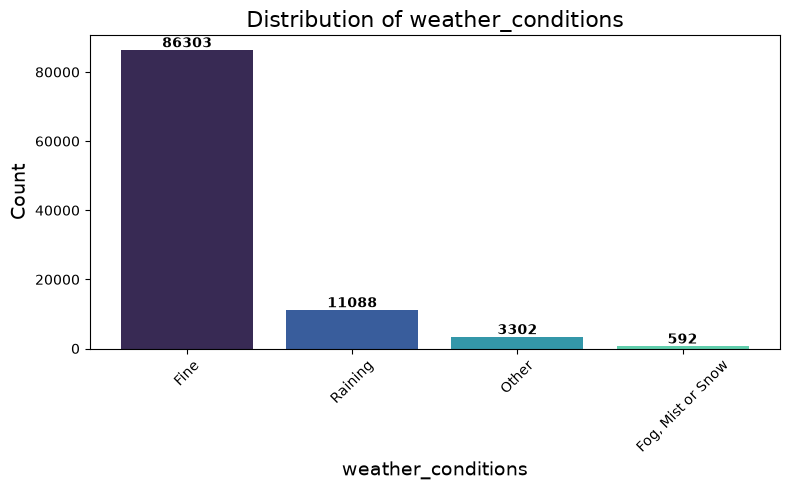

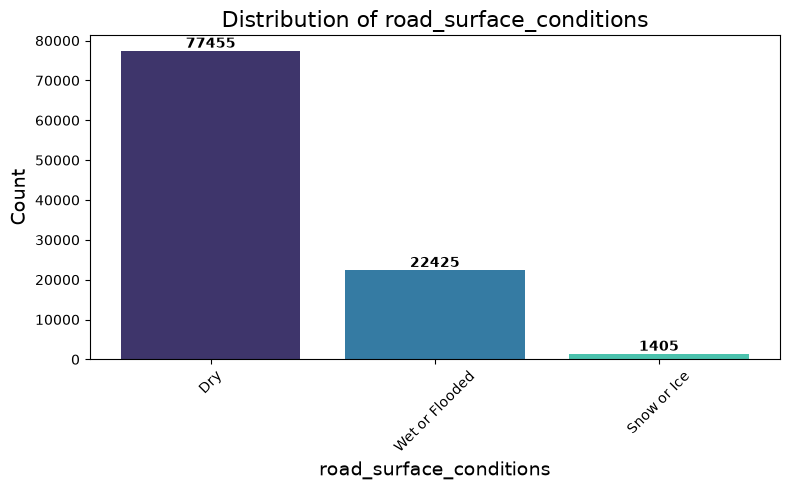

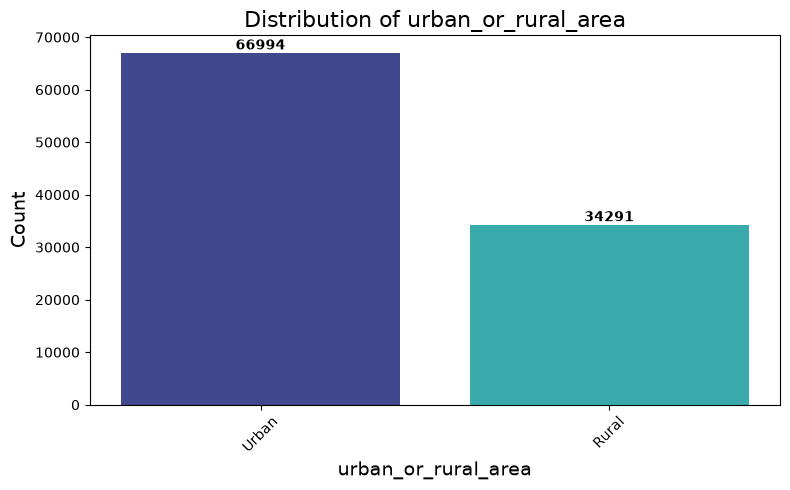

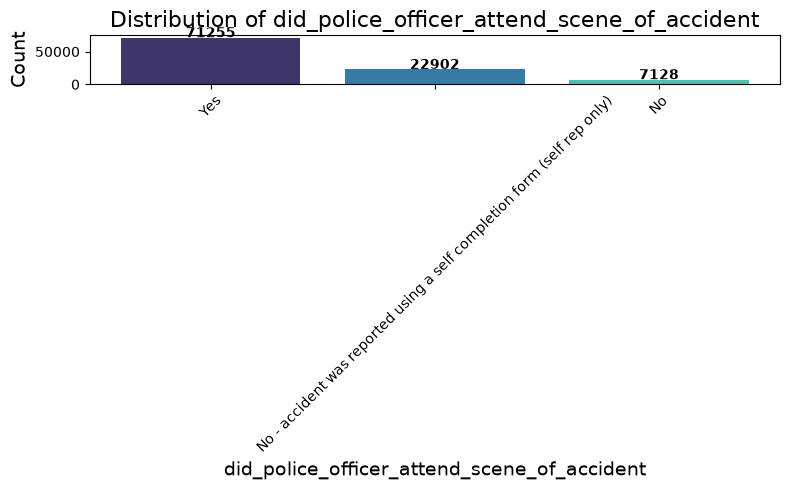

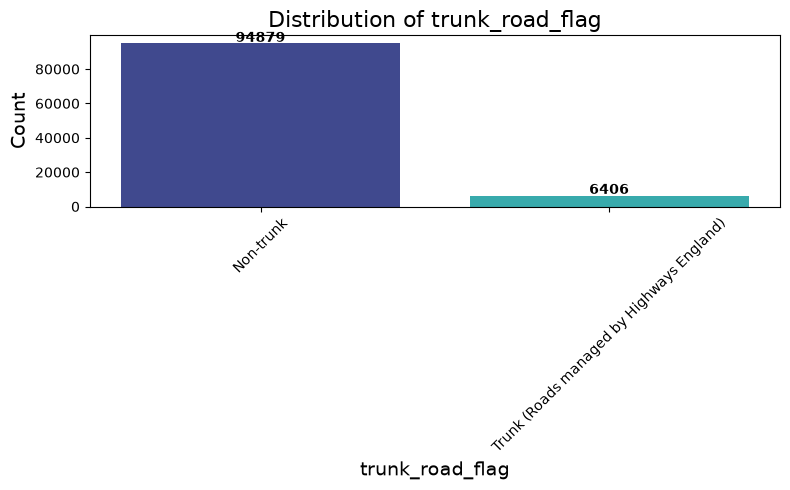

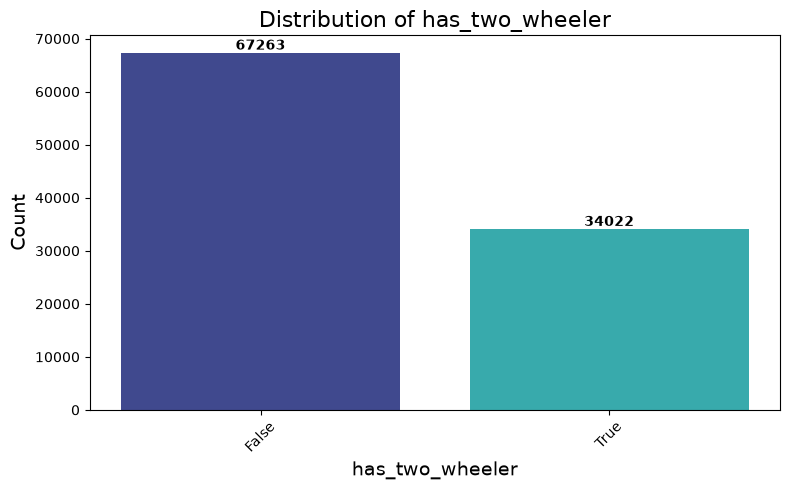

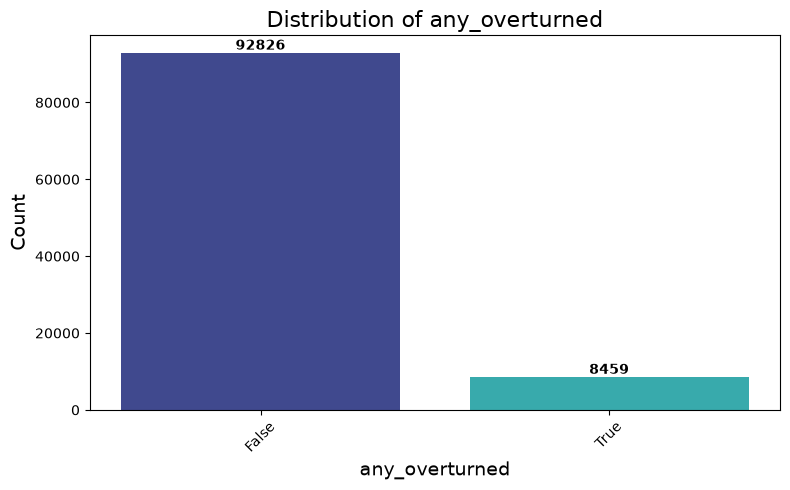

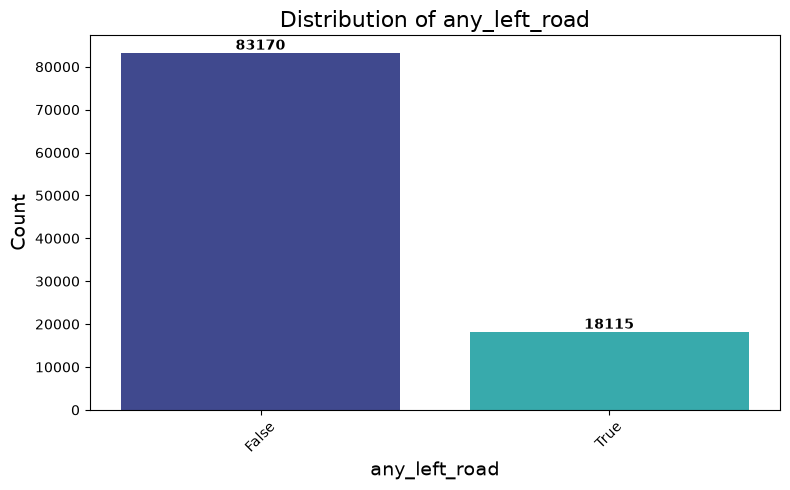

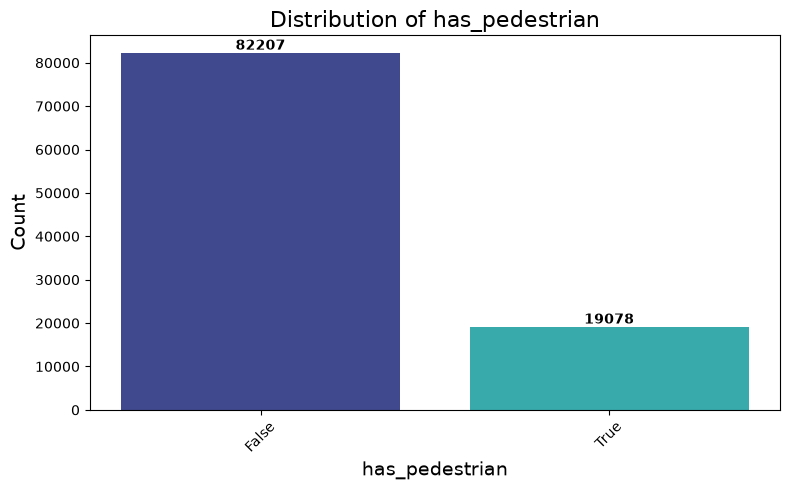

In [50]:
def plot_single_category(col):
    plt.figure(figsize=(8,5))
    counts = df[col].value_counts()
    plt.bar(counts.index.astype(str), counts.values, color=sns.color_palette("mako", len(counts)))
    for i, v in enumerate(counts.values):
        plt.text(i, v + counts.max()*0.01, f'{v}', ha='center', fontweight='bold', fontsize=10)
    plt.title(f'Distribution of {col}', fontsize=16)
    plt.xlabel(col, fontsize=14)
    plt.ylabel('Count', fontsize=14)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

for col in catcols:
    plot_single_category(col)

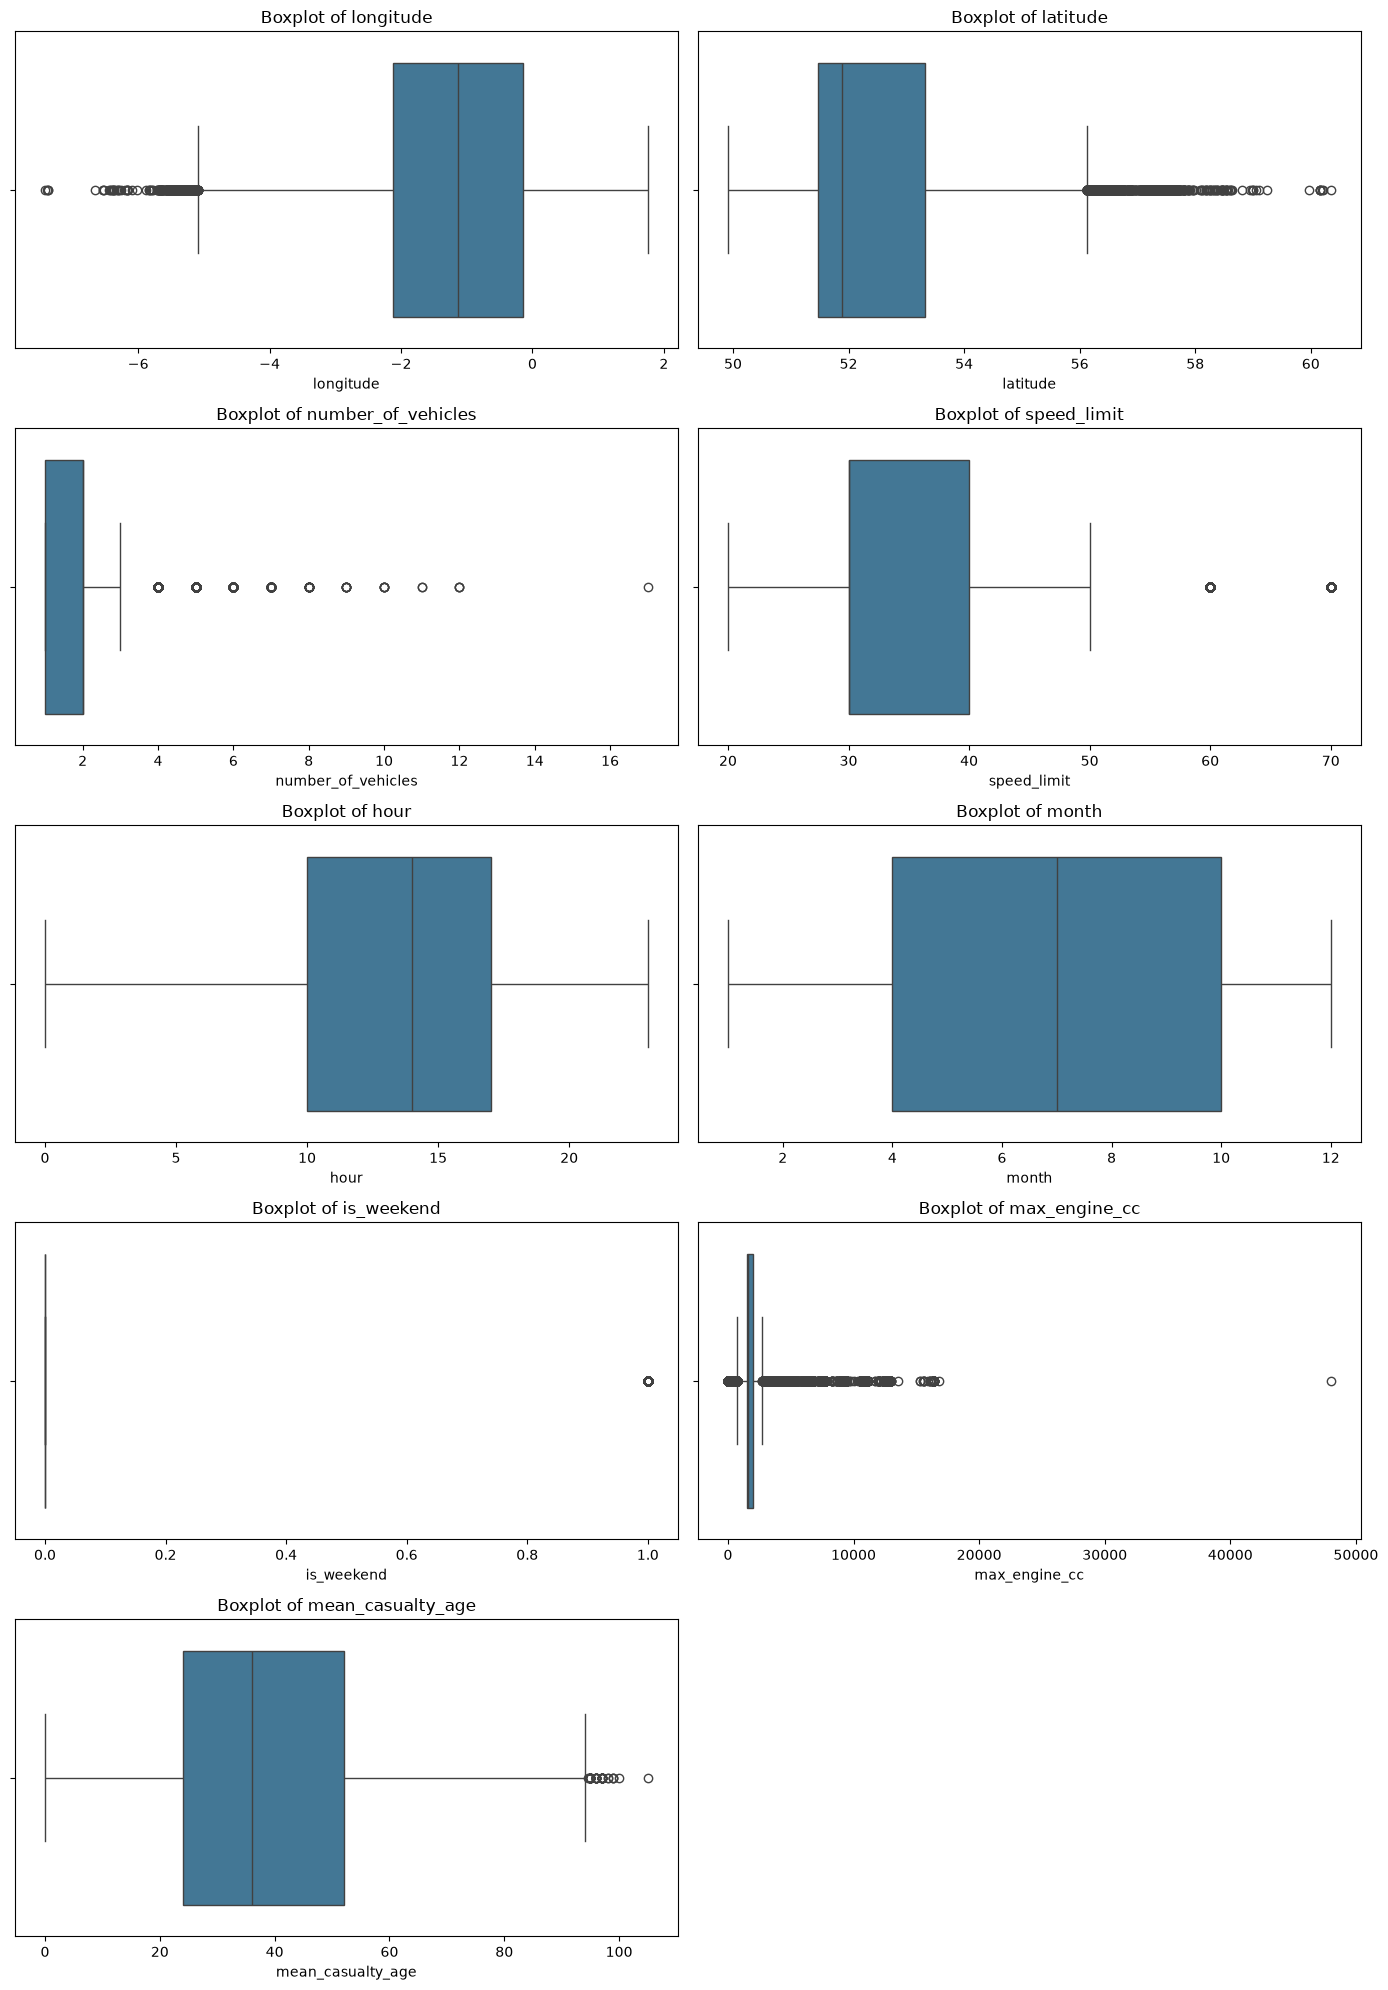

In [51]:
import math

rows = math.ceil(len(numcols) / 2)

fig, axes = plt.subplots(rows, 2, figsize=(14, 4*rows))
axes = axes.flatten()

for i, col in enumerate(numcols):
    sns.boxplot(data=df, x=col, ax=axes[i], color=sns.color_palette("mako", 3)[1])
    axes[i].set_title(f'Boxplot of {col}', fontsize=12)
    axes[i].set_xlabel(col, fontsize=10)

for i in range(len(numcols), len(axes)):
    fig.delaxes(axes[i])

plt.subplots_adjust(wspace=0.4, hspace=0.6)
plt.tight_layout()
plt.show()

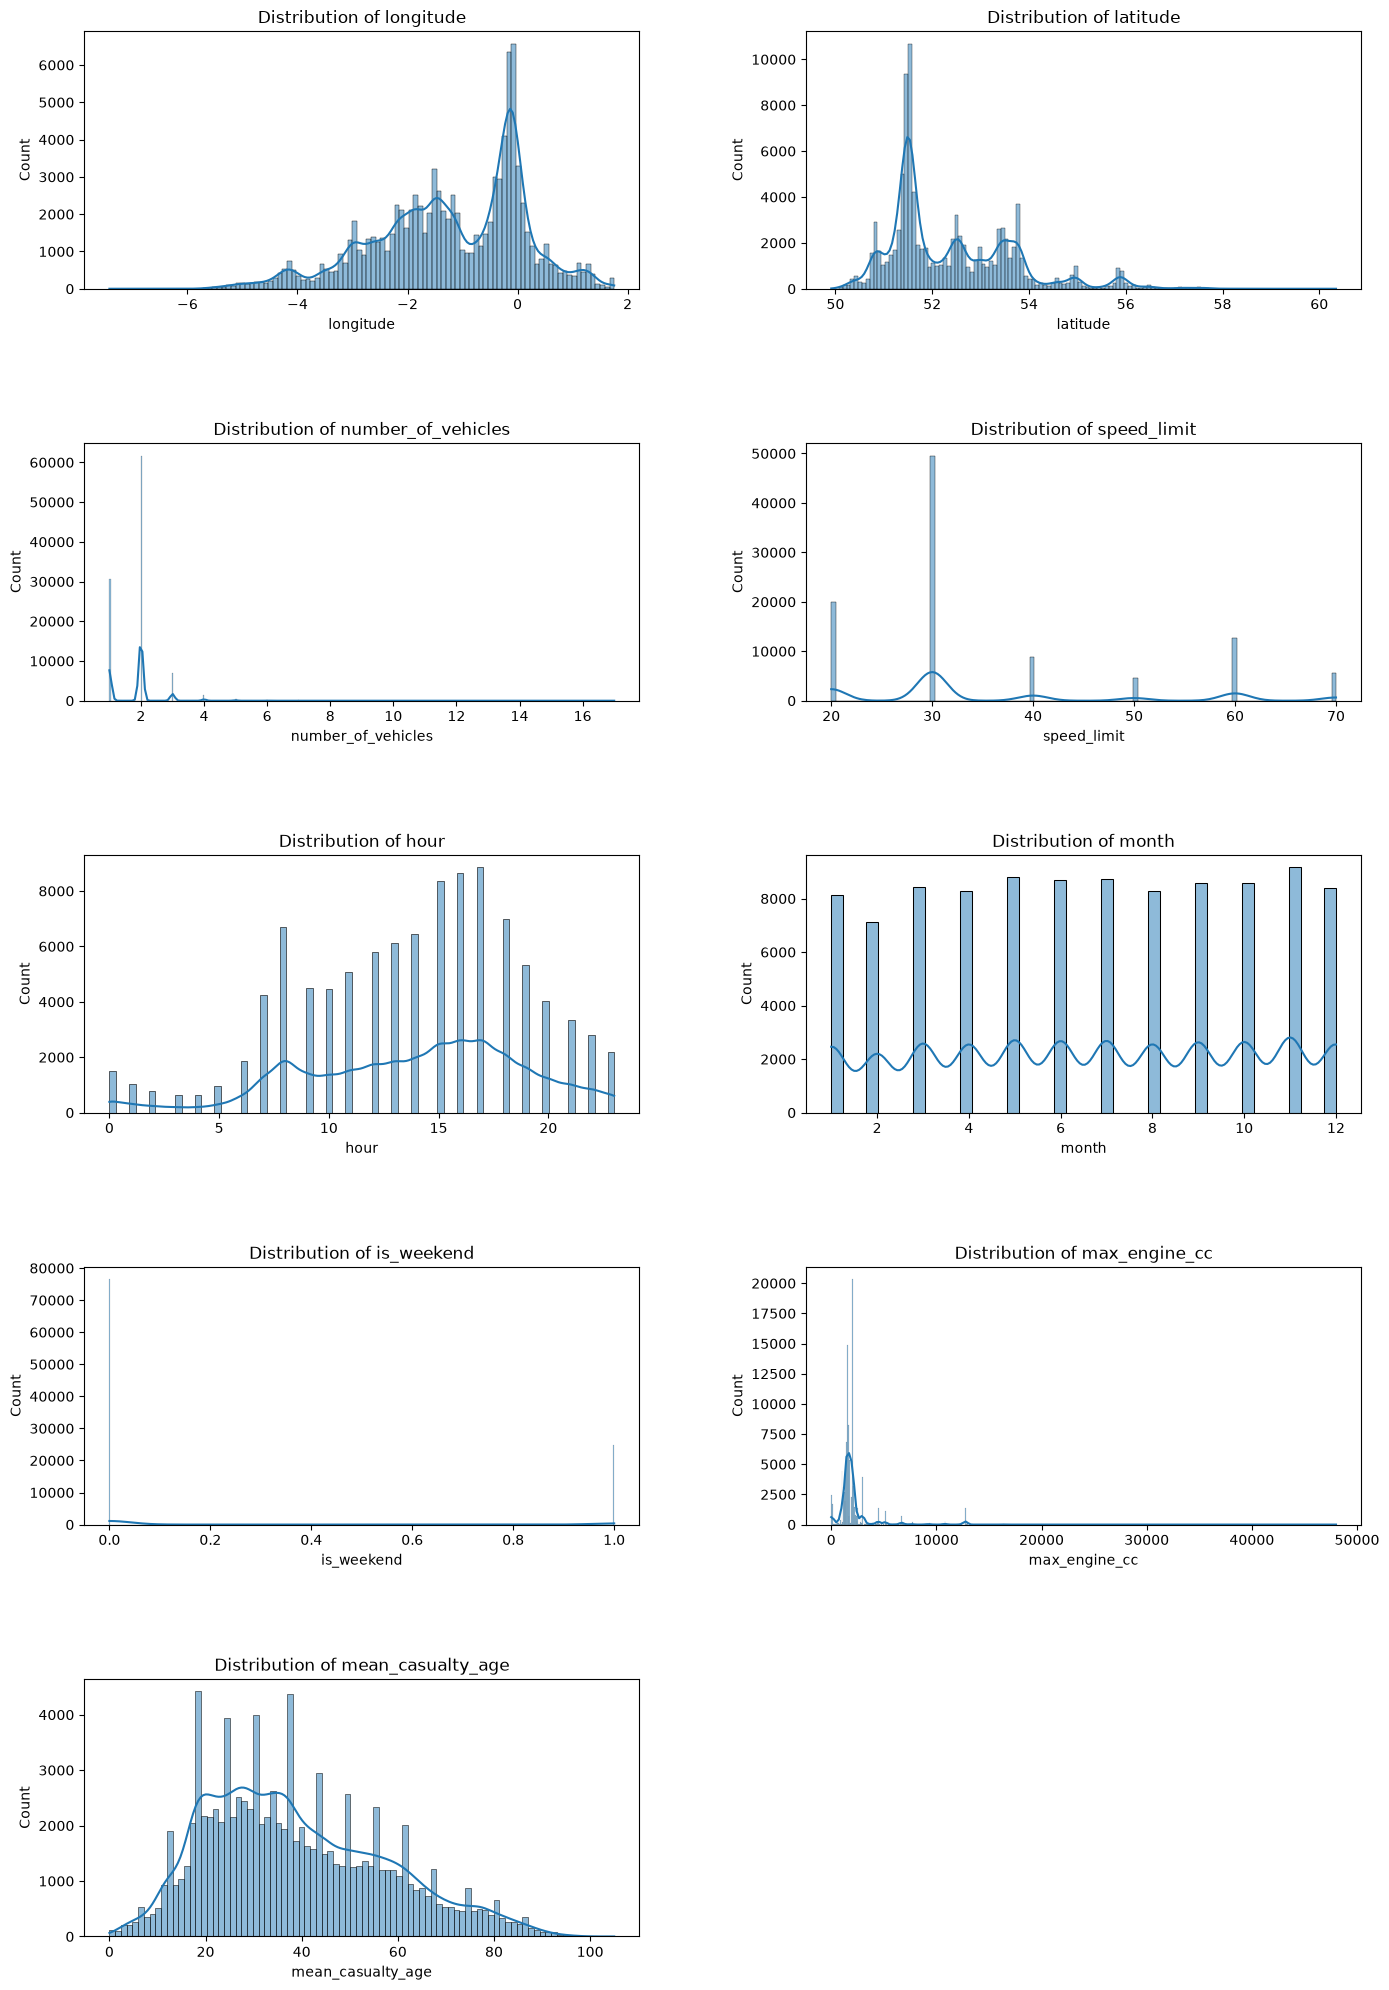

In [52]:
rows = math.ceil(len(numcols) / 2)

fig, axes = plt.subplots(rows, 2, figsize=(14, 4*rows))
axes = axes.flatten()

for i, col in enumerate(numcols):
    axes[i].set_title(f'Distribution of {col}')
    sns.histplot(data=df, x=col, kde=True, ax=axes[i])

for i in range(len(numcols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
fig.subplots_adjust(wspace=0.3, hspace=0.6)
plt.show()

<Axes: >

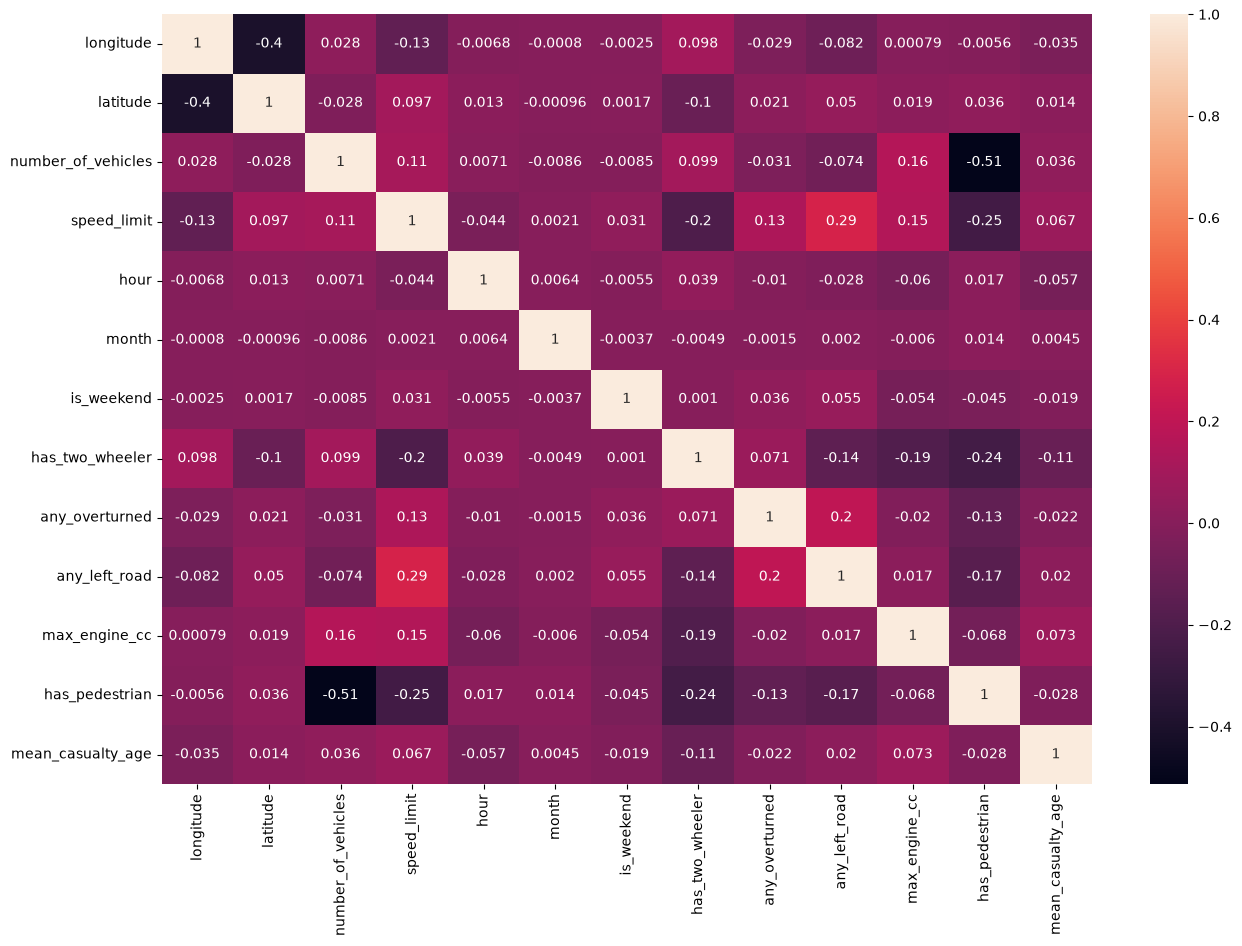

In [53]:
correlation = df.corr(numeric_only=True)
plt.figure(figsize=(15,10))
sns.heatmap(correlation,annot=True)

## Encoding

In [54]:
# 1. Target: ordinal, severity increases
df["collision_severity"] = df["collision_severity"].map({"Slight": 0, "Serious": 1, "Fatal": 2})

# 2. Binary -> 0/1
df["urban_or_rural_area"] = df["urban_or_rural_area"].map({"Rural": 0, "Urban": 1})
df["trunk_road_flag"] = df["trunk_road_flag"].map({
    "Non-trunk": 0,
    "Trunk (Roads managed by Highways England)": 1,
})

# 3. Ordinal -> ordered integers (higher = more dangerous)
df["light_conditions"] = df["light_conditions"].map({
    "Daylight": 0,
    "Darkness - lights lit": 1,
    "Darkness - lighting unknown": 2,
    "Darkness - Unlit or No Lighting": 3,
})
df["road_surface_conditions"] = df["road_surface_conditions"].map({
    "Dry": 0,
    "Wet or Flooded": 1,
    "Snow or Ice": 2,
})

# 4. Boolean -> 0/1
bool_cols = ["has_two_wheeler", "any_overturned", "any_left_road", "has_pedestrian"]
df[bool_cols] = df[bool_cols].astype(int)

# 5. Nominal (no order) -> One-Hot
nominal_cols = [
    "first_road_class", "second_road_class", "road_type", "junction_detail",
    "pedestrian_crossing", "weather_conditions",
    "did_police_officer_attend_scene_of_accident",
]
df = pd.get_dummies(df, columns=nominal_cols, dtype=int)

print("NaN values:", int(df.isna().sum().sum()))
print(df.shape)

NaN values: 0
(101285, 53)


## Training & Evaluation

In [55]:
x=df.drop('collision_severity',axis=1)
y=df['collision_severity']

In [56]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=42,stratify=y)

In [57]:

print("Number of vehicles:")
print(x_train['number_of_vehicles'].value_counts().sort_index().tail(10))

print("\nEngine Capacity above 10000:")
print(x_train.loc[
    x_train['max_engine_cc'] > 10000,
    'max_engine_cc'
].value_counts().sort_index())

print("\nCasualty Age:")
print(x_train['mean_casualty_age'].describe())

Number of vehicles:
number_of_vehicles
4     1038
5      340
6       81
7       51
8       12
9        4
10       3
11       2
12       2
17       1
Name: count, dtype: int64

Engine Capacity above 10000:
max_engine_cc
10518.0     11
10521.0      2
10667.0     11
10677.0     54
10800.0      2
10824.0      1
10837.0    211
10838.0      3
11120.0     17
11705.0      1
11946.0      1
11967.0      4
12000.0      4
12130.0      2
12170.0      1
12400.0      1
12419.0    129
12600.0      2
12700.0      2
12740.0     75
12742.0    622
12777.0    296
12780.0      2
12809.0     97
12882.0     12
12900.0     13
12902.0    187
13000.0      3
13500.0      1
15256.0      2
15569.0      2
15600.0      2
15607.0      1
15927.0      1
16123.0      2
16353.0     30
16400.0     10
Name: count, dtype: int64

Casualty Age:
count    81028.000000
mean        38.725935
std         18.673849
min          0.000000
25%         24.000000
50%         36.000000
75%         52.000000
max        105.000000
Name: mea

In [58]:
print("number_of_vehicles rows above 8 (train):", int((x_train["number_of_vehicles"] > 8).sum()))
print("max_engine_cc rows above 20000 (train):", int((x_train["max_engine_cc"] > 20000).sum()))
print("max_engine_cc min (train):", x_train["max_engine_cc"].min())
print("mean_casualty_age min/max (train):", x_train["mean_casualty_age"].min(), x_train["mean_casualty_age"].max())

for part in (x_train, x_test):
    part["number_of_vehicles"] = part["number_of_vehicles"].clip(upper=8)
    part["max_engine_cc"] = np.log1p(part["max_engine_cc"].clip(upper=20000))
    part["mean_casualty_age"] = part["mean_casualty_age"].clip(lower=0, upper=100)

print("max_engine_cc after clip+log1p, train mean/max:",
      round(x_train["max_engine_cc"].mean(), 3), round(x_train["max_engine_cc"].max(), 3))

number_of_vehicles rows above 8 (train): 12
max_engine_cc rows above 20000 (train): 0
max_engine_cc min (train): 0.0
mean_casualty_age min/max (train): 0.0 105.0
max_engine_cc after clip+log1p, train mean/max: 7.316 9.705


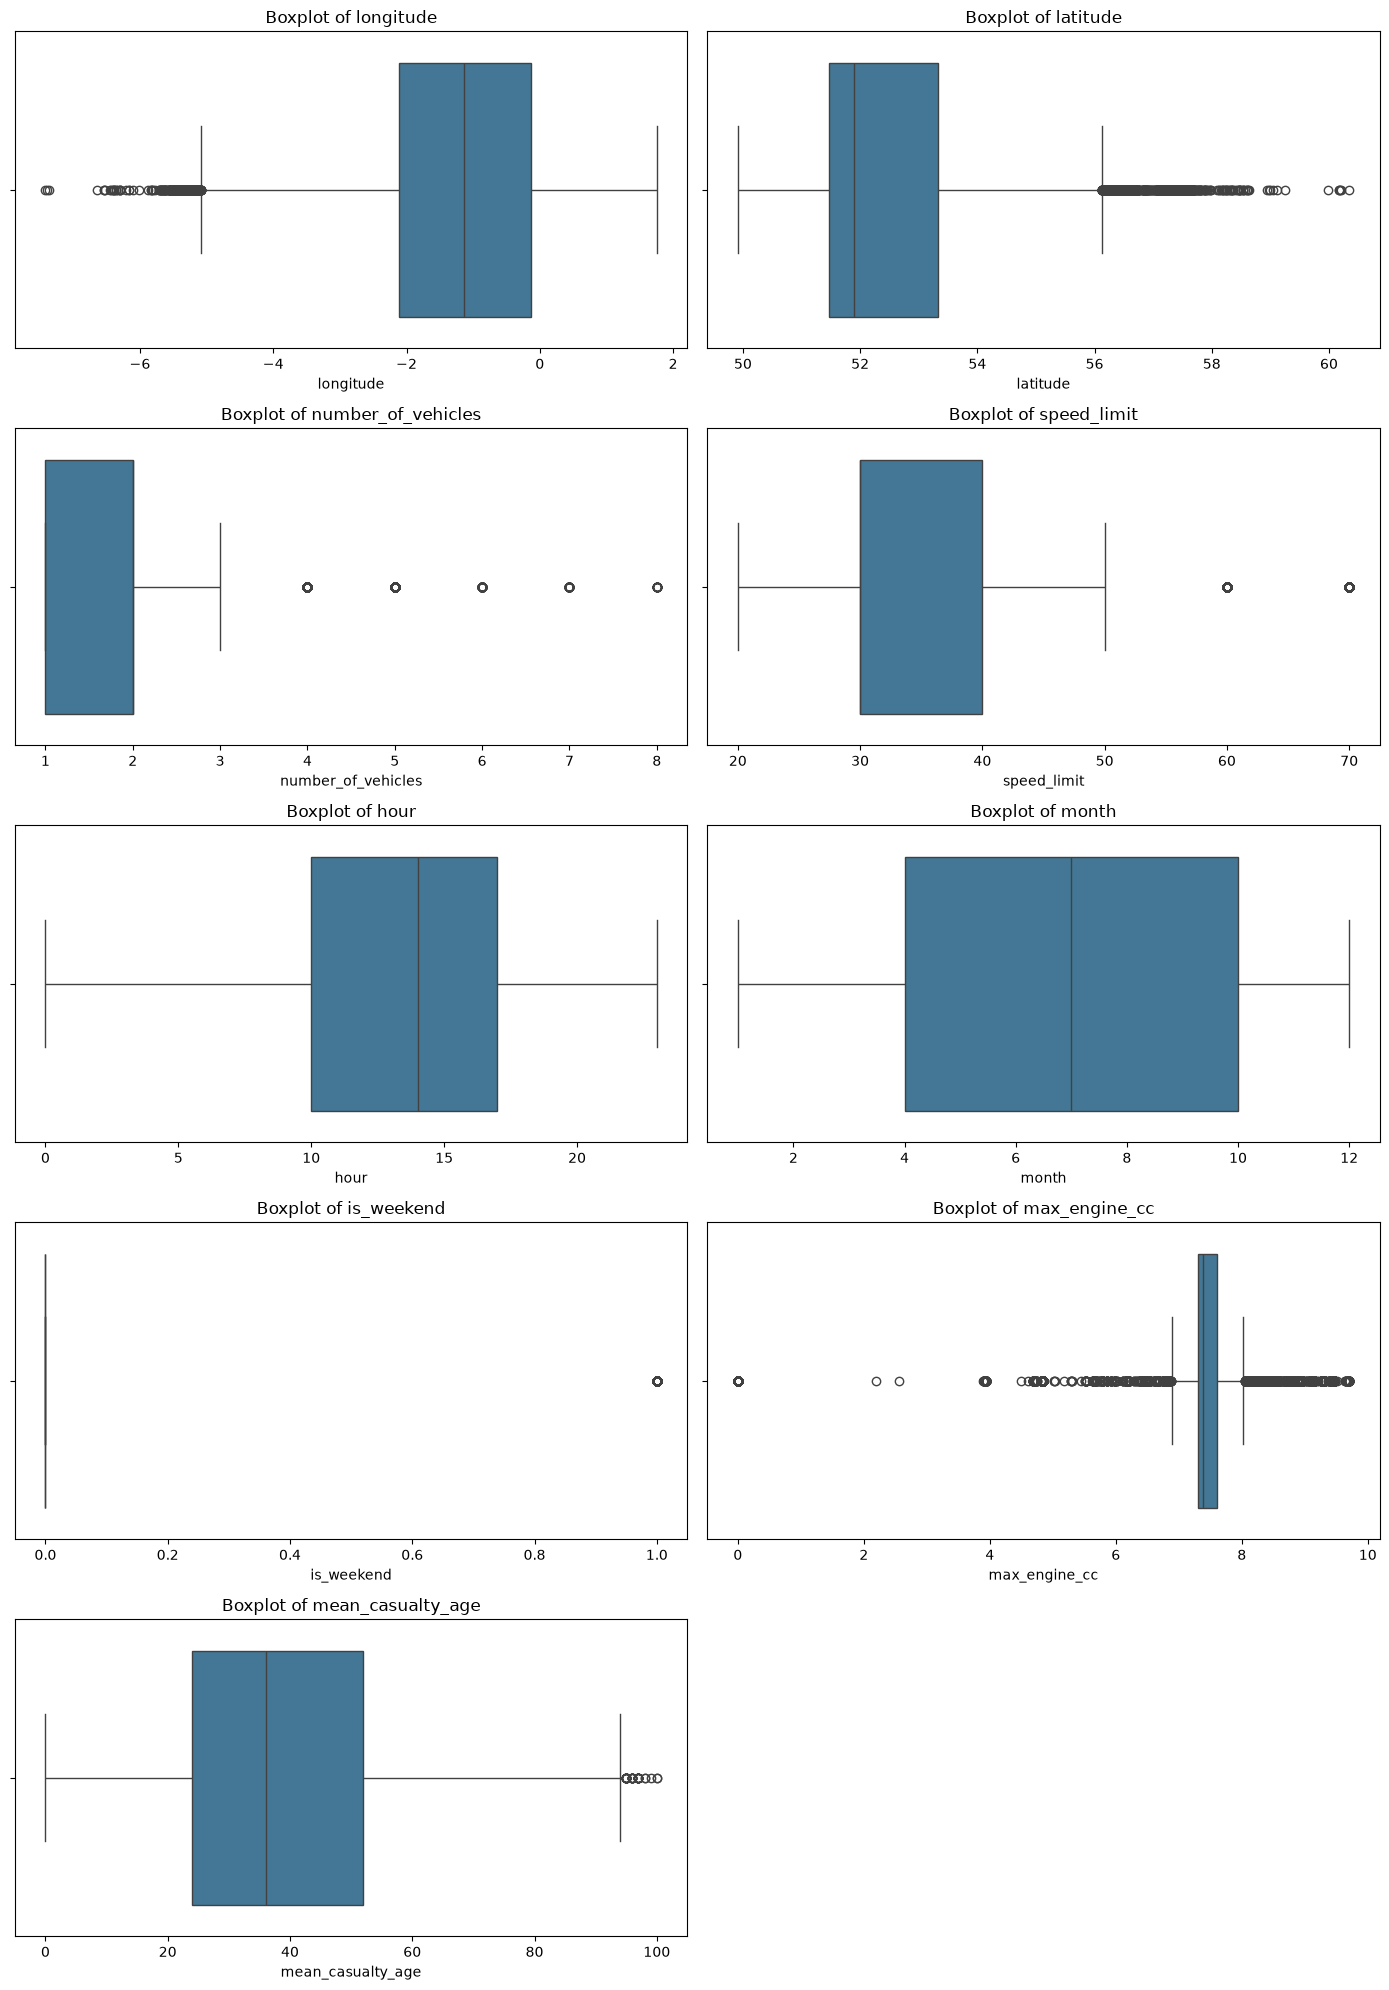

In [59]:
rows = math.ceil(len(numcols) / 2)

fig, axes = plt.subplots(rows, 2, figsize=(14, 4*rows))
axes = axes.flatten()

for i, col in enumerate(numcols):
    sns.boxplot(data=x_train, x=col, ax=axes[i], color=sns.color_palette("mako", 3)[1])
    axes[i].set_title(f'Boxplot of {col}', fontsize=12)
    axes[i].set_xlabel(col, fontsize=10)

for i in range(len(numcols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [60]:
x_train.info()

<class 'pandas.DataFrame'>
Index: 81028 entries, 80849 to 72375
Data columns (total 52 columns):
 #   Column                                                                                                               Non-Null Count  Dtype  
---  ------                                                                                                               --------------  -----  
 0   longitude                                                                                                            81028 non-null  float64
 1   latitude                                                                                                             81028 non-null  float64
 2   number_of_vehicles                                                                                                   81028 non-null  int64  
 3   speed_limit                                                                                                          81028 non-null  int64  
 4   light_conditions      

In [61]:
x_test

,longitude,latitude,number_of_vehicles,speed_limit,light_conditions,road_surface_conditions,urban_or_rural_area,trunk_road_flag,hour,month,...,pedestrian_crossing_Pedestrian light crossing (pelican or puffin or toucan or similar),pedestrian_crossing_Pedestrian phase at traffic signal,pedestrian_crossing_Zebra crossing,weather_conditions_Fine,"weather_conditions_Fog, Mist or Snow",weather_conditions_Other,weather_conditions_Raining,did_police_officer_attend_scene_of_accident_No,did_police_officer_attend_scene_of_accident_No - accident was reported using a self completion form (self rep only),did_police_officer_attend_scene_of_accident_Yes
31972,-0.58050,51.42476,3,30,0,0,1,0,17,8,...,0,0,0,1,0,0,0,0,0,1
42831,-0.38026,53.74372,1,30,0,0,1,0,16,6,...,0,0,0,1,0,0,0,1,0,0
99828,-1.73164,53.68553,1,40,1,0,1,0,2,7,...,0,0,0,1,0,0,0,1,0,0
9770,-2.30969,53.40029,2,30,0,1,1,0,13,7,...,0,0,0,1,0,0,0,0,1,0
2972,0.12547,51.47054,3,30,0,0,1,0,15,11,...,0,0,0,1,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72269,-1.46637,53.53889,2,30,0,0,1,0,12,10,...,0,0,0,1,0,0,0,0,0,1
11838,0.11425,51.50449,3,30,3,0,1,0,18,10,...,0,0,0,1,0,0,0,0,0,1
23407,-0.56866,51.30666,2,30,0,0,1,0,13,4,...,0,0,0,1,0,0,0,0,0,1
61400,-0.19299,51.54293,2,20,0,0,1,0,12,6,...,0,0,0,1,0,0,0,0,0,1


In [62]:
num_cols = [
    "longitude", "latitude", "number_of_vehicles", "speed_limit",
    "hour", "month", "max_engine_cc", "mean_casualty_age"]

scaler = StandardScaler()

x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

x_train_scaled[num_cols] = scaler.fit_transform(x_train[num_cols])   
x_test_scaled[num_cols] = scaler.transform(x_test[num_cols])         


In [63]:
from imblearn.over_sampling import SMOTE

x_sm_s, y_sm_s = SMOTE(sampling_strategy={2: 5000}, k_neighbors=5, random_state=42).fit_resample(x_train_scaled, y_train)
x_sm_r, y_sm_r = SMOTE(sampling_strategy={2: 5000}, k_neighbors=5, random_state=42).fit_resample(x_train, y_train)

In [64]:
def train_evaluate(model,x_train,x_test,y_train,y_test):
  model.fit(x_train,y_train)
  y_pred=model.predict(x_test)
  y_pred_train=model.predict(x_train)
  print('Evaluate on Testing dataset')
  print("Accuracy score: ",accuracy_score(y_test,y_pred))
  print()
  print("Classification Report :" )
  print(classification_report(y_test,y_pred))
  print()
  cm=confusion_matrix(y_test,y_pred)
  sns.heatmap(cm,annot=True,fmt='d')
  plt.show()

  print('_'*60)

  print('Evluation on Training dataset')
  print("Accuracy Score : ",accuracy_score(y_train,y_pred_train))
  print()
  print("Classification Report : ")
  print(classification_report(y_train,y_pred_train))
  print()
  cm = confusion_matrix(y_train,y_pred_train)
  sns.heatmap(cm,annot = True,fmt = 'd')
  plt.show()


 *--* Logistic Regression Model *--*
Evaluate on Testing dataset
Accuracy score:  0.7439403662931332

Classification Report :
              precision    recall  f1-score   support

           0       0.76      0.97      0.85     14935
           1       0.52      0.11      0.18      5032
           2       1.00      0.00      0.01       290

    accuracy                           0.74     20257
   macro avg       0.76      0.36      0.35     20257
weighted avg       0.70      0.74      0.67     20257




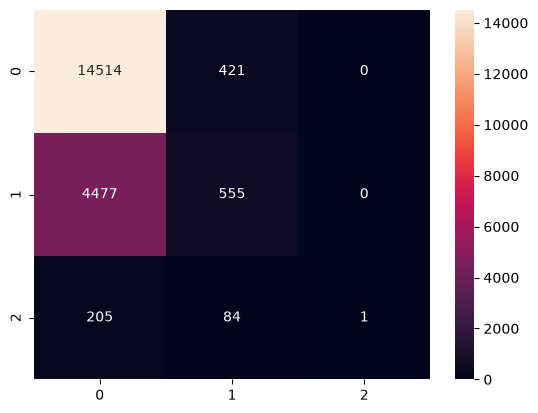

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.7426692007701041

Classification Report : 
              precision    recall  f1-score   support

           0       0.75      0.97      0.85     59741
           1       0.52      0.11      0.18     20129
           2       0.53      0.01      0.02      1158

    accuracy                           0.74     81028
   macro avg       0.60      0.36      0.35     81028
weighted avg       0.69      0.74      0.67     81028




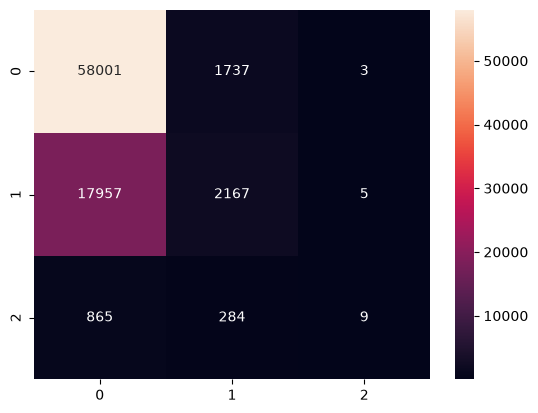

 *--* Logistic Regression Model *--*
Evaluate on Testing dataset
Accuracy score:  0.7439403662931332

Classification Report :
              precision    recall  f1-score   support

           0       0.76      0.97      0.85     14935
           1       0.52      0.11      0.18      5032
           2       1.00      0.00      0.01       290

    accuracy                           0.74     20257
   macro avg       0.76      0.36      0.35     20257
weighted avg       0.70      0.74      0.67     20257




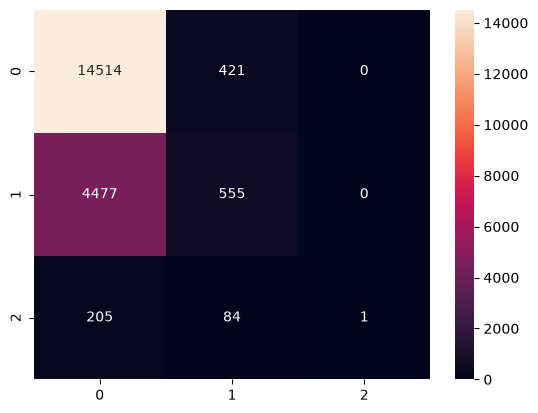

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.7426692007701041

Classification Report : 
              precision    recall  f1-score   support

           0       0.75      0.97      0.85     59741
           1       0.52      0.11      0.18     20129
           2       0.53      0.01      0.02      1158

    accuracy                           0.74     81028
   macro avg       0.60      0.36      0.35     81028
weighted avg       0.69      0.74      0.67     81028




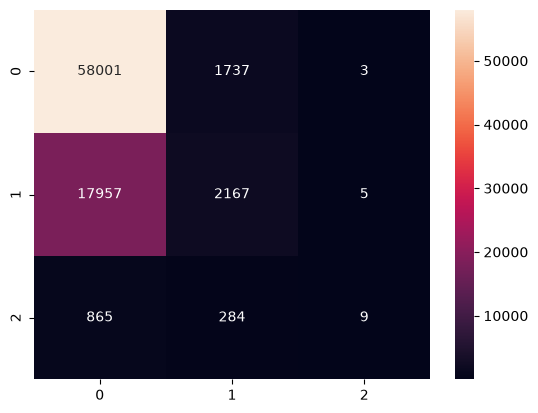

 *--* Logistic Regression Model + Class Weight + SMOTE *--*
Evaluate on Testing dataset
Accuracy score:  0.5401589573974429

Classification Report :
              precision    recall  f1-score   support

           0       0.85      0.59      0.70     14935
           1       0.34      0.38      0.36      5032
           2       0.04      0.65      0.08       290

    accuracy                           0.54     20257
   macro avg       0.41      0.54      0.38     20257
weighted avg       0.71      0.54      0.60     20257




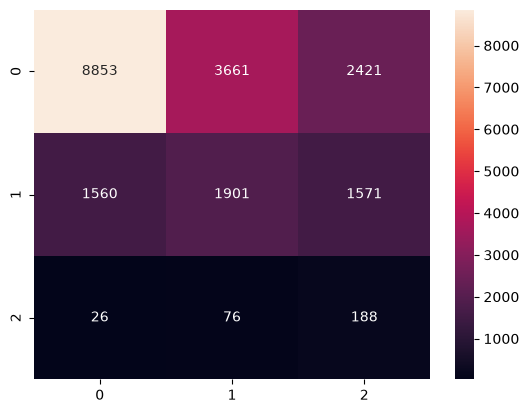

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.5460087870859456

Classification Report : 
              precision    recall  f1-score   support

           0       0.85      0.60      0.70     59741
           1       0.35      0.38      0.36     20129
           2       0.05      0.74      0.10      1158

    accuracy                           0.55     81028
   macro avg       0.42      0.57      0.39     81028
weighted avg       0.71      0.55      0.61     81028




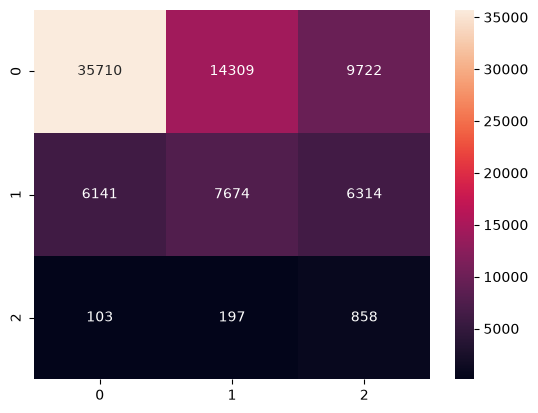

 *--* Logistic Regression + SMOTE *--*
Evaluate on Testing dataset
Accuracy score:  0.7435454410820951

Classification Report :
              precision    recall  f1-score   support

           0       0.76      0.97      0.85     14935
           1       0.52      0.11      0.18      5032
           2       0.38      0.03      0.05       290

    accuracy                           0.74     20257
   macro avg       0.55      0.37      0.36     20257
weighted avg       0.69      0.74      0.67     20257




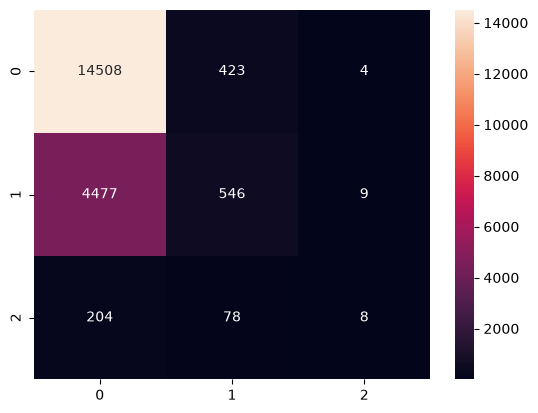

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.7413573700954401

Classification Report : 
              precision    recall  f1-score   support

           0       0.75      0.97      0.84     59741
           1       0.50      0.11      0.17     20129
           2       0.97      0.56      0.71      5000

    accuracy                           0.74     84870
   macro avg       0.74      0.54      0.58     84870
weighted avg       0.70      0.74      0.68     84870




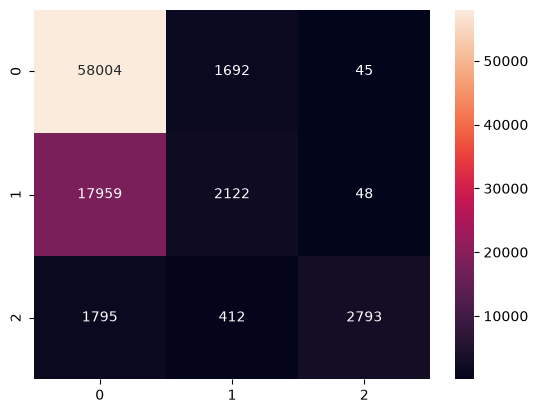

In [65]:
lr = LogisticRegression(C=1, max_iter=1000, random_state=42)
lr_b = LogisticRegression(C=1, max_iter=1000,class_weight="balanced", random_state=42)

print(" *--* Logistic Regression Model *--*")

train_evaluate(lr, x_train_scaled, x_test_scaled, y_train, y_test)

print(" *--* Logistic Regression Model *--*")
train_evaluate(lr, x_train_scaled, x_test_scaled, y_train, y_test)

# ---- SMOTE version ----
print(" *--* Logistic Regression Model + Class Weight + SMOTE *--*")
train_evaluate(lr_b, x_train_scaled, x_test_scaled, y_train, y_test)

print(" *--* Logistic Regression + SMOTE *--*")
train_evaluate(lr,x_sm_s, x_test_scaled, y_sm_s, y_test)

#دا كويس اوى

   *---* Naive Bayes Model *---*
Evaluate on Testing dataset
Accuracy score:  0.4317026213160883

Classification Report :
              precision    recall  f1-score   support

           0       0.82      0.52      0.64     14935
           1       0.35      0.16      0.22      5032
           2       0.02      0.73      0.05       290

    accuracy                           0.43     20257
   macro avg       0.40      0.47      0.30     20257
weighted avg       0.69      0.43      0.52     20257




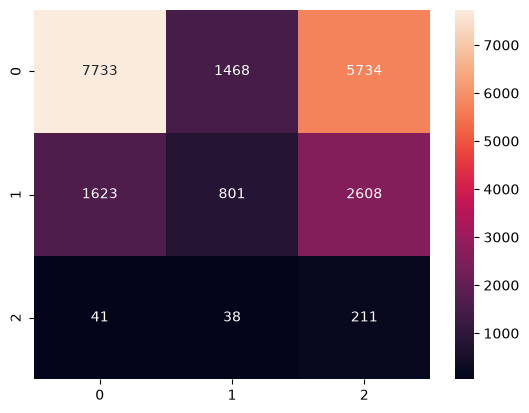

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.4371698672063978

Classification Report : 
              precision    recall  f1-score   support

           0       0.83      0.52      0.64     59741
           1       0.35      0.16      0.22     20129
           2       0.03      0.81      0.05      1158

    accuracy                           0.44     81028
   macro avg       0.40      0.50      0.30     81028
weighted avg       0.70      0.44      0.53     81028




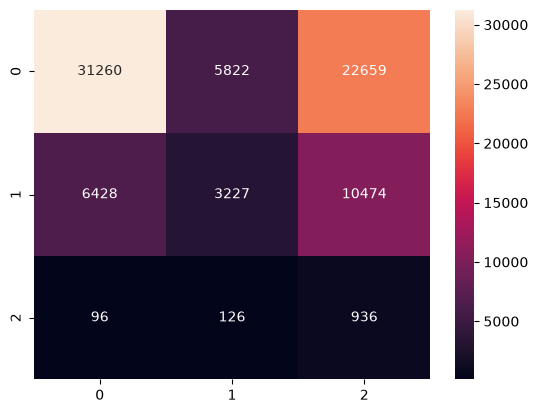

   *---* Naive Bayes + SMOTE *---*
Evaluate on Testing dataset
Accuracy score:  0.45929802043737966

Classification Report :
              precision    recall  f1-score   support

           0       0.82      0.54      0.65     14935
           1       0.34      0.22      0.27      5032
           2       0.03      0.66      0.05       290

    accuracy                           0.46     20257
   macro avg       0.40      0.47      0.32     20257
weighted avg       0.69      0.46      0.55     20257




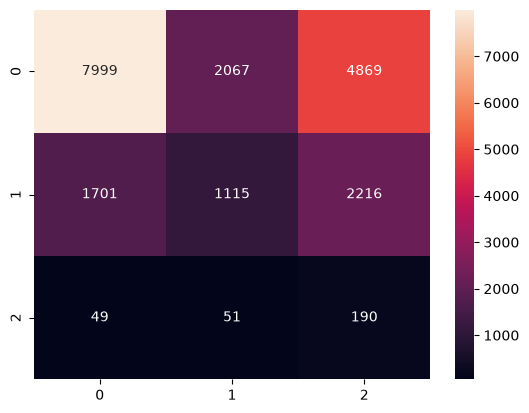

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.4874985271591846

Classification Report : 
              precision    recall  f1-score   support

           0       0.82      0.54      0.65     59741
           1       0.34      0.22      0.27     20129
           2       0.14      0.90      0.24      5000

    accuracy                           0.49     84870
   macro avg       0.43      0.55      0.39     84870
weighted avg       0.67      0.49      0.54     84870




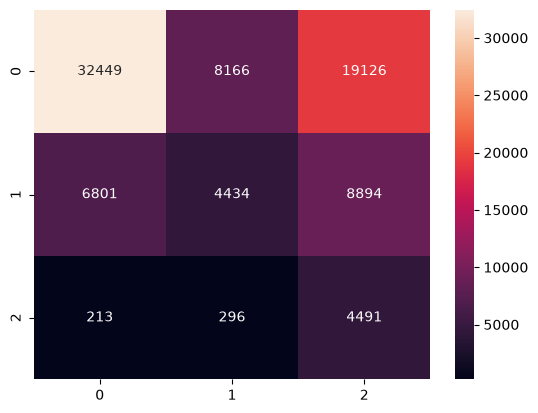

In [66]:
nb = GaussianNB()

print("   *---* Naive Bayes Model *---*")

train_evaluate(nb, x_train, x_test, y_train, y_test)

# ---- SMOTE version ----
print("   *---* Naive Bayes + SMOTE *---*")

train_evaluate(nb, x_sm_r, x_test, y_sm_r, y_test)

   *---* KNN Model *---*
Evaluate on Testing dataset
Accuracy score:  0.7161968702177025

Classification Report :
              precision    recall  f1-score   support

           0       0.76      0.90      0.83     14935
           1       0.41      0.21      0.28      5032
           2       0.00      0.00      0.00       290

    accuracy                           0.72     20257
   macro avg       0.39      0.37      0.37     20257
weighted avg       0.66      0.72      0.68     20257




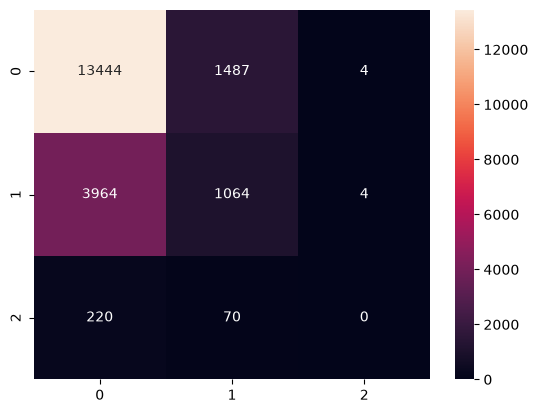

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.7879004788468184

Classification Report : 
              precision    recall  f1-score   support

           0       0.81      0.95      0.87     59741
           1       0.68      0.37      0.47     20129
           2       0.66      0.03      0.05      1158

    accuracy                           0.79     81028
   macro avg       0.71      0.45      0.47     81028
weighted avg       0.77      0.79      0.76     81028




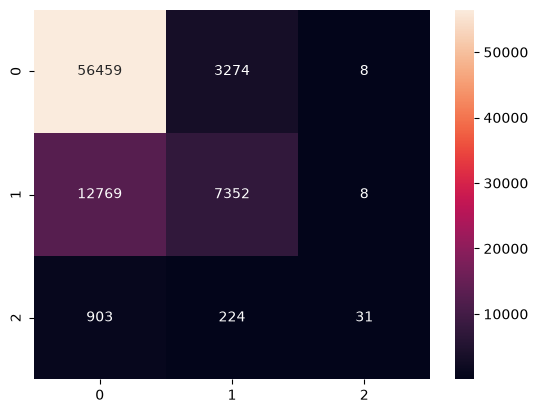

   *---* KNN + SMOTE *---*
Evaluate on Testing dataset
Accuracy score:  0.7033618008589624

Classification Report :
              precision    recall  f1-score   support

           0       0.77      0.88      0.82     14935
           1       0.40      0.20      0.27      5032
           2       0.06      0.11      0.08       290

    accuracy                           0.70     20257
   macro avg       0.41      0.40      0.39     20257
weighted avg       0.67      0.70      0.67     20257




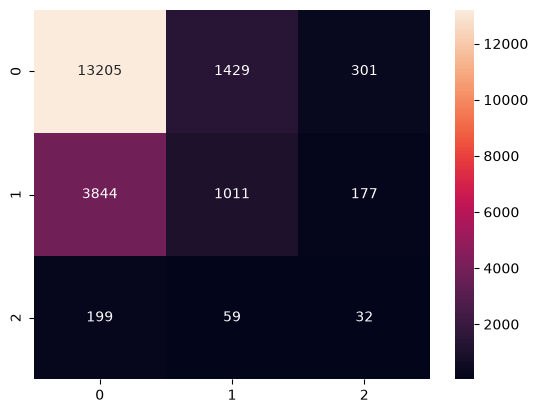

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.7997879109225875

Classification Report : 
              precision    recall  f1-score   support

           0       0.81      0.94      0.87     59741
           1       0.69      0.36      0.47     20129
           2       0.82      0.94      0.88      5000

    accuracy                           0.80     84870
   macro avg       0.77      0.75      0.74     84870
weighted avg       0.79      0.80      0.78     84870




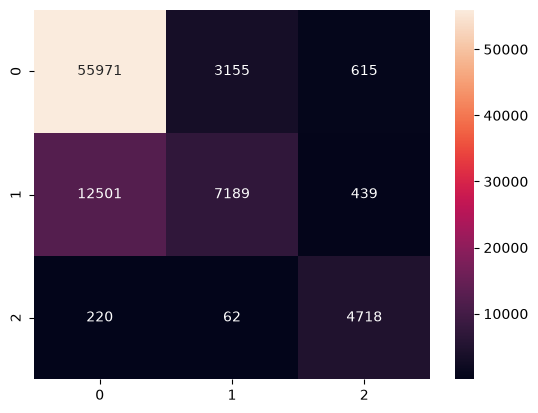

In [67]:
knn = KNeighborsClassifier(n_neighbors=5,weights='uniform')
print("   *---* KNN Model *---*")

train_evaluate(knn,x_train_scaled,x_test_scaled,y_train,y_test)

# ---- SMOTE version ----
print("   *---* KNN + SMOTE *---*")

train_evaluate(knn, x_sm_s, x_test_scaled, y_sm_s, y_test)

   *---* Random Forest Model *---*
Evaluate on Testing dataset
Accuracy score:  0.7423112997976008

Classification Report :
              precision    recall  f1-score   support

           0       0.75      0.99      0.85     14935
           1       0.58      0.04      0.08      5032
           2       0.00      0.00      0.00       290

    accuracy                           0.74     20257
   macro avg       0.44      0.35      0.31     20257
weighted avg       0.69      0.74      0.65     20257




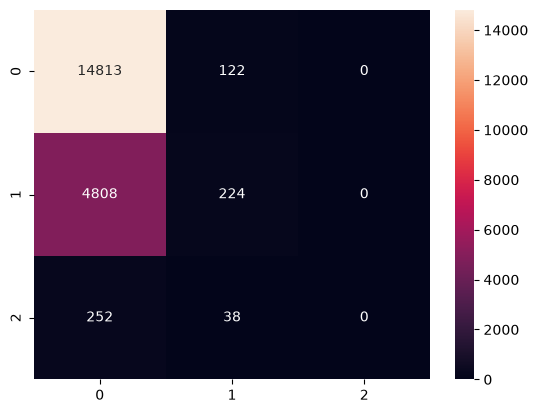

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.7505923878165572

Classification Report : 
              precision    recall  f1-score   support

           0       0.75      0.99      0.86     59741
           1       0.76      0.07      0.13     20129
           2       1.00      0.00      0.00      1158

    accuracy                           0.75     81028
   macro avg       0.84      0.35      0.33     81028
weighted avg       0.76      0.75      0.66     81028




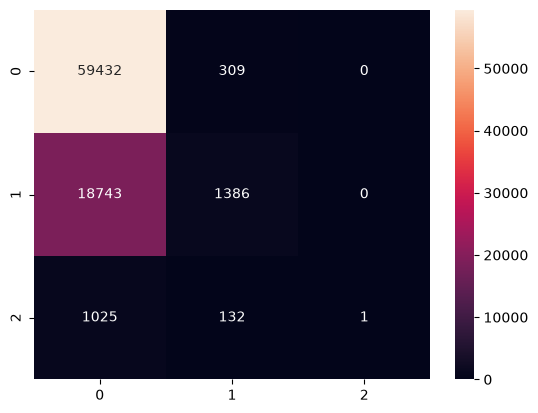

   *---* Random Forest + SMOTE *---*
Evaluate on Testing dataset
Accuracy score:  0.7420151058893222

Classification Report :
              precision    recall  f1-score   support

           0       0.74      0.99      0.85     14935
           1       0.59      0.04      0.07      5032
           2       0.00      0.00      0.00       290

    accuracy                           0.74     20257
   macro avg       0.45      0.34      0.31     20257
weighted avg       0.70      0.74      0.65     20257




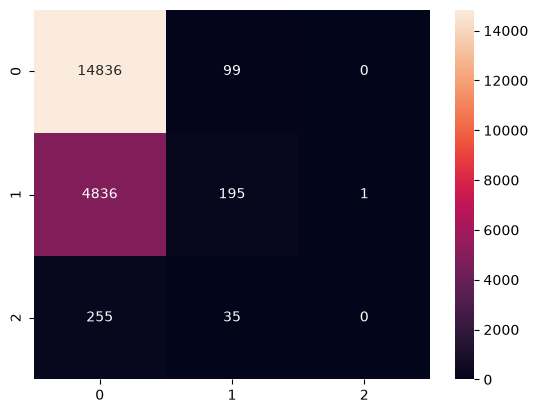

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.7251325556733829

Classification Report : 
              precision    recall  f1-score   support

           0       0.72      1.00      0.84     59741
           1       0.72      0.06      0.11     20129
           2       1.00      0.17      0.28      5000

    accuracy                           0.73     84870
   macro avg       0.81      0.41      0.41     84870
weighted avg       0.74      0.73      0.63     84870




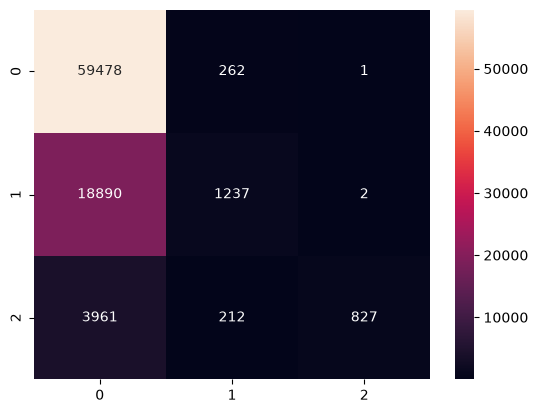

In [68]:
rf = RandomForestClassifier(n_estimators=100,max_depth=10,random_state=42)
print("   *---* Random Forest Model *---*")

train_evaluate(rf,x_train,x_test,y_train,y_test)

# ---- SMOTE version ----
print("   *---* Random Forest + SMOTE *---*")

train_evaluate(rf, x_sm_r, x_test, y_sm_r, y_test)

   *---*XGBoost Model *---*
Evaluate on Testing dataset
Accuracy score:  0.7473465962383373

Classification Report :
              precision    recall  f1-score   support

           0       0.76      0.96      0.85     14935
           1       0.53      0.15      0.24      5032
           2       0.30      0.02      0.04       290

    accuracy                           0.75     20257
   macro avg       0.53      0.38      0.38     20257
weighted avg       0.70      0.75      0.69     20257




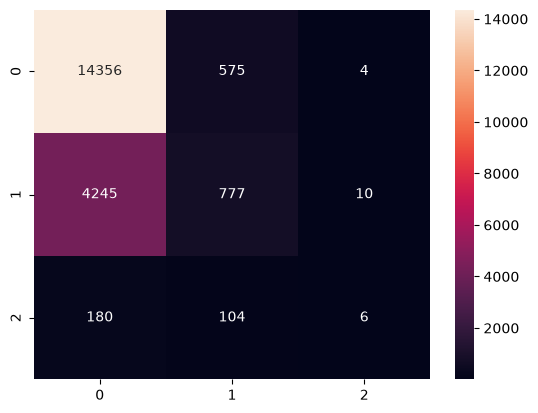

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.7579848941106778

Classification Report : 
              precision    recall  f1-score   support

           0       0.77      0.97      0.86     59741
           1       0.61      0.17      0.27     20129
           2       0.72      0.06      0.11      1158

    accuracy                           0.76     81028
   macro avg       0.70      0.40      0.41     81028
weighted avg       0.73      0.76      0.70     81028




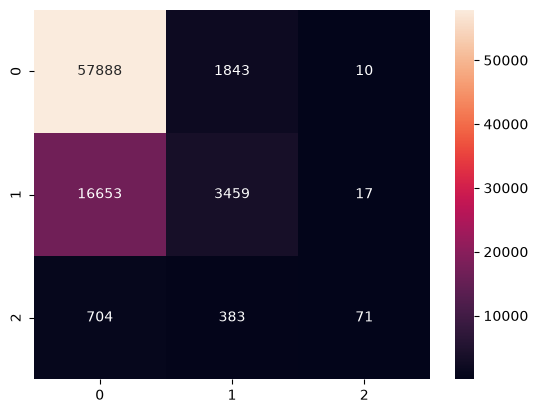

   *---*XGBoost + SMOTE *---*
Evaluate on Testing dataset
Accuracy score:  0.7491731253393888

Classification Report :
              precision    recall  f1-score   support

           0       0.76      0.96      0.85     14935
           1       0.55      0.15      0.24      5032
           2       0.33      0.01      0.02       290

    accuracy                           0.75     20257
   macro avg       0.55      0.38      0.37     20257
weighted avg       0.71      0.75      0.69     20257




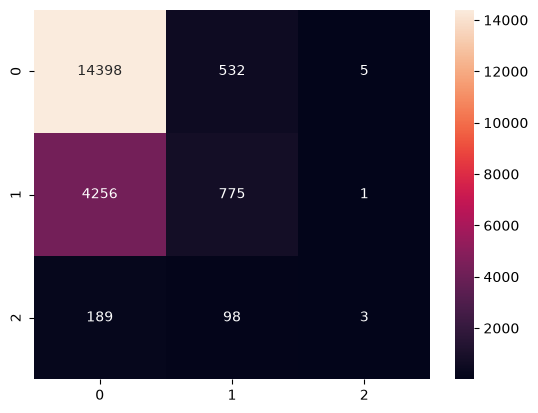

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.7594202898550725

Classification Report : 
              precision    recall  f1-score   support

           0       0.76      0.97      0.85     59741
           1       0.59      0.17      0.26     20129
           2       1.00      0.63      0.78      5000

    accuracy                           0.76     84870
   macro avg       0.78      0.59      0.63     84870
weighted avg       0.74      0.76      0.71     84870




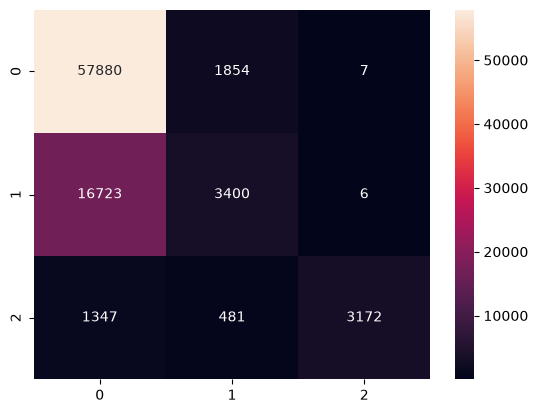

In [76]:
from xgboost import XGBClassifier
xgboost = XGBClassifier( n_estimators=200,max_depth=5,learning_rate=0.05,subsample=1,colsample_bytree=1)
print("   *---*XGBoost Model *---*")

train_evaluate(xgboost,x_train,x_test,y_train,y_test)

# ---- SMOTE version ----
print("   *---*XGBoost + SMOTE *---*")

train_evaluate(xgboost, x_sm_r, x_test, y_sm_r, y_test)

   *---* Decision Tree Model *---*
Evaluate on Testing dataset
Accuracy score:  0.7040529199782791

Classification Report :
              precision    recall  f1-score   support

           0       0.77      0.86      0.82     14935
           1       0.39      0.27      0.32      5032
           2       0.20      0.03      0.05       290

    accuracy                           0.70     20257
   macro avg       0.45      0.39      0.39     20257
weighted avg       0.67      0.70      0.68     20257




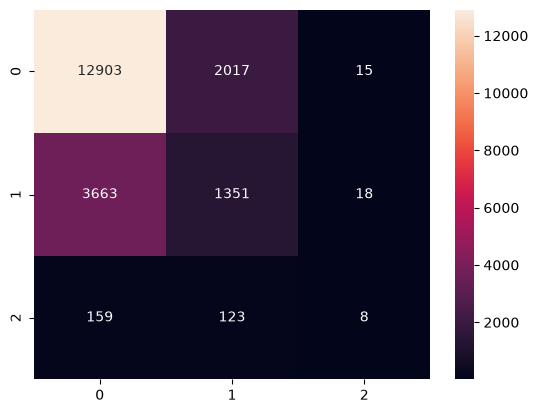

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.7938737226637705

Classification Report : 
              precision    recall  f1-score   support

           0       0.82      0.93      0.87     59741
           1       0.65      0.44      0.53     20129
           2       0.54      0.09      0.15      1158

    accuracy                           0.79     81028
   macro avg       0.67      0.48      0.52     81028
weighted avg       0.78      0.79      0.78     81028




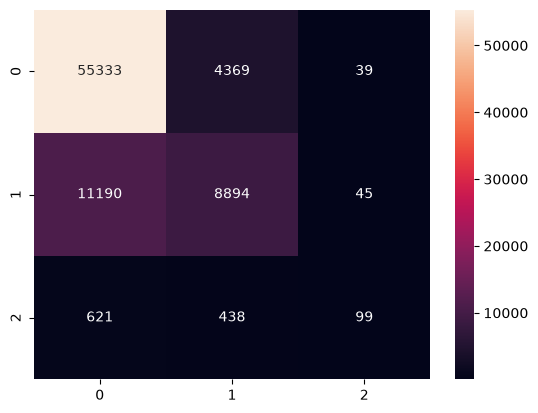

   *---* Decision Tree + SMOTE *---*
Evaluate on Testing dataset
Accuracy score:  0.697635385298909

Classification Report :
              precision    recall  f1-score   support

           0       0.77      0.86      0.81     14935
           1       0.39      0.25      0.30      5032
           2       0.07      0.10      0.08       290

    accuracy                           0.70     20257
   macro avg       0.41      0.40      0.40     20257
weighted avg       0.67      0.70      0.68     20257




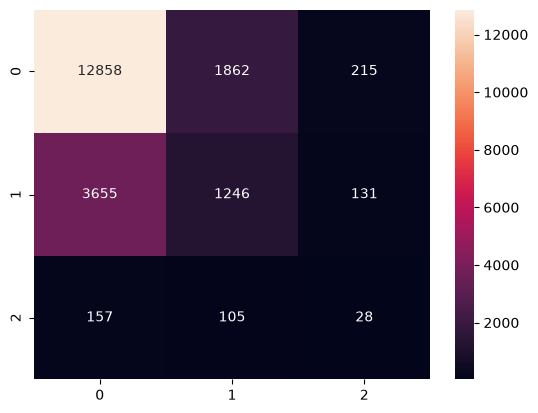

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.7819842111464593

Classification Report : 
              precision    recall  f1-score   support

           0       0.81      0.92      0.86     59741
           1       0.63      0.41      0.50     20129
           2       0.78      0.64      0.70      5000

    accuracy                           0.78     84870
   macro avg       0.74      0.66      0.69     84870
weighted avg       0.77      0.78      0.77     84870




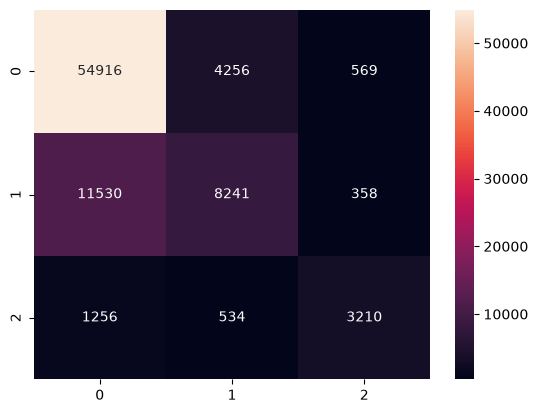

In [70]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=None,
    min_samples_leaf=5,
    min_samples_split=50,
    random_state=42,
)
print("   *---* Decision Tree Model *---*")

train_evaluate(dt, x_train, x_test, y_train, y_test)

# ---- SMOTE version ----
print("   *---* Decision Tree + SMOTE *---*")

train_evaluate(dt, x_sm_r, x_test, y_sm_r, y_test)

In [71]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score



model = Sequential([
    Dense(128, activation='relu', input_shape=(x_train_scaled.shape[1],)),
    Dropout(0.3),

    Dense(64, activation='relu'),
    Dropout(0.2),

    Dense(32, activation='relu'),

    Dense(3, activation='softmax')
])


model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

print(" *---* Neural Network Model *---*")


history = model.fit(
    x_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)


y_pred = model.predict(x_test_scaled).argmax(axis=1)


print(classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

 *---* Neural Network Model *---*
Epoch 1/50
2026/2026 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7381 - loss: 0.5936 - val_accuracy: 0.7431 - val_loss: 0.5727
Epoch 2/50
2026/2026 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.7422 - loss: 0.5738 - val_accuracy: 0.7417 - val_loss: 0.5735
Epoch 3/50
2026/2026 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.7445 - loss: 0.5706 - val_accuracy: 0.7444 - val_loss: 0.5838
Epoch 4/50
2026/2026 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.7451 - loss: 0.5674 - val_accuracy: 0.7448 - val_loss: 0.5663
Epoch 5/50
2026/2026 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.7450 - loss: 0.5655 - val_accuracy: 0.7438 - val_loss: 0.5646
Epoch 6/50
2026/2026 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7470 - loss: 0.5631 - val_accuracy: 0.7433 - val_loss: 0.5655
Epoch 7/50
2026/2026 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7475 - loss: 0.5612 - val_accuracy: 0.7448 - val_loss: 0.5645
Epoch 8/50
2026/2026 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - 

   *---* Neural Network (MLP) Model *---*
Evaluate on Testing dataset
Accuracy score:  0.7468529397245397

Classification Report :
              precision    recall  f1-score   support

           0       0.76      0.96      0.85     14935
           1       0.54      0.14      0.23      5032
           2       0.00      0.00      0.00       290

    accuracy                           0.75     20257
   macro avg       0.43      0.37      0.36     20257
weighted avg       0.70      0.75      0.68     20257




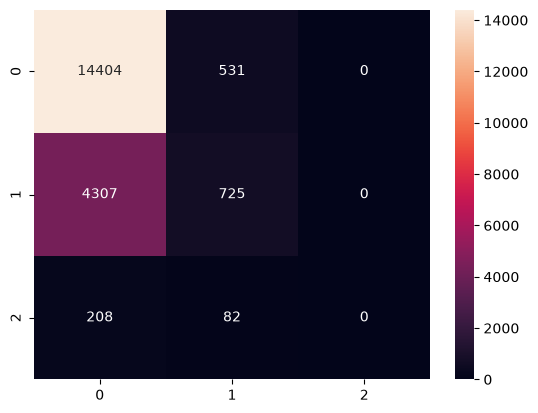

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.7482968850273979

Classification Report : 
              precision    recall  f1-score   support

           0       0.76      0.97      0.85     59741
           1       0.55      0.14      0.23     20129
           2       0.00      0.00      0.00      1158

    accuracy                           0.75     81028
   macro avg       0.44      0.37      0.36     81028
weighted avg       0.70      0.75      0.68     81028




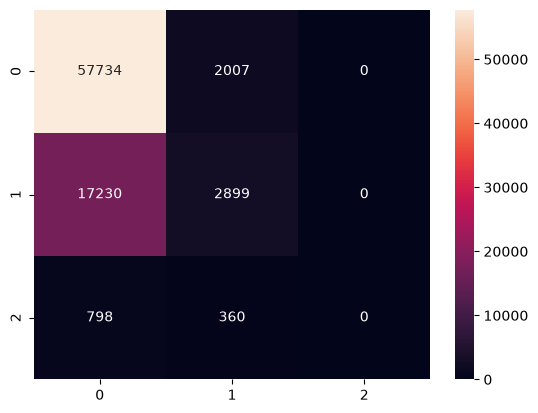

   *---* Neural Network (MLP) + SMOTE *---*
Evaluate on Testing dataset
Accuracy score:  0.7426568593572592

Classification Report :
              precision    recall  f1-score   support

           0       0.76      0.97      0.85     14935
           1       0.53      0.12      0.20      5032
           2       0.12      0.06      0.08       290

    accuracy                           0.74     20257
   macro avg       0.47      0.38      0.37     20257
weighted avg       0.69      0.74      0.68     20257




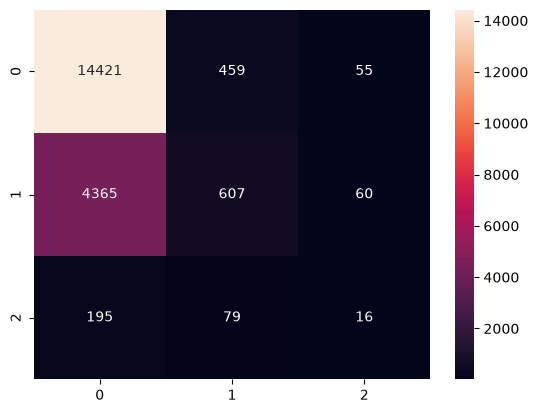

____________________________________________________________
Evluation on Training dataset
Accuracy Score :  0.7613290915517851

Classification Report : 
              precision    recall  f1-score   support

           0       0.76      0.97      0.85     59741
           1       0.61      0.14      0.23     20129
           2       0.94      0.72      0.82      5000

    accuracy                           0.76     84870
   macro avg       0.77      0.61      0.63     84870
weighted avg       0.74      0.76      0.70     84870




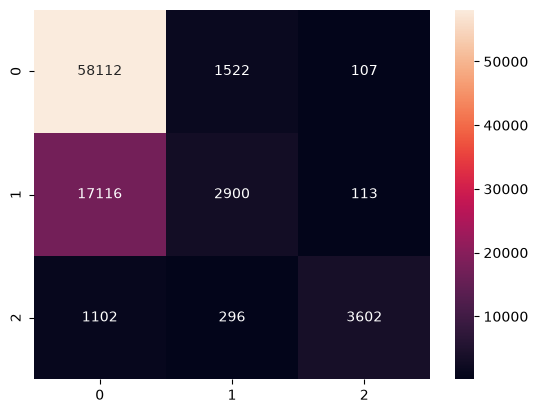

In [72]:
nn = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42
)

print("   *---* Neural Network (MLP) Model *---*")

train_evaluate(nn, x_train_scaled, x_test_scaled, y_train, y_test)

# ---- SMOTE version ----
print("   *---* Neural Network (MLP) + SMOTE *---*")

train_evaluate(nn, x_sm_s, x_test_scaled, y_sm_s, y_test)

In [74]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

models = {
    "XGbbost": XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, subsample=1, colsample_bytree=1),
    "Logistic Regression": LogisticRegression(C=1, max_iter=1000, class_weight="balanced", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5, weights="uniform"),
    "Decision Tree": DecisionTreeClassifier(criterion="entropy", max_depth=None, min_samples_leaf=5, min_samples_split=50, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(128, 64, 32), activation="relu", solver="adam",
                                          alpha=0.0001, learning_rate_init=0.001, max_iter=200,
                                          early_stopping=True, validation_fraction=0.1,
                                          n_iter_no_change=10, random_state=42),
}

results = []

for name, model in models.items():

    model.fit(x_train, y_train)

    y_pred = model.predict(x_test)
    y_pred_train = model.predict(x_train)

    results.append({
        "Model": name,
        "Testing Accuracy": accuracy_score(y_test, y_pred),
        "Training Accuracy": accuracy_score(y_train, y_pred_train),
        "Precision": precision_score(y_test, y_pred, average='weighted'),
        "Recall": recall_score(y_test, y_pred, average='weighted'),
        "F1 Score": f1_score(y_test, y_pred, average='weighted')
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Testing Accuracy",
    ascending=False
)

print(results_df)

                  Model  Testing Accuracy  Training Accuracy  Precision  \
6     Gradient Boosting          0.748976           0.750654   0.703935   
0               XGbbost          0.748531           0.748112   0.702459   
8  Neural Network (MLP)          0.746014           0.746409   0.698049   
4         Random Forest          0.742311           0.750592   0.694458   
5              AdaBoost          0.741620           0.740374   0.685617   
3         Decision Tree          0.704053           0.793874   0.667720   
2                   KNN          0.703312           0.780965   0.640680   
1   Logistic Regression          0.538036           0.544232   0.709092   
7           Naive Bayes          0.431703           0.437170   0.693322   

     Recall  F1 Score  
6  0.748976  0.685909  
0  0.748531  0.680785  
8  0.746014  0.679905  
4  0.742311  0.648063  
5  0.741620  0.650670  
3  0.704053  0.680396  
2  0.703312  0.659422  
1  0.538036  0.602987  
7  0.431703  0.523537  


In [75]:
results = []

for name, model in models.items():

    model.fit(x_sm_r, y_sm_r)
    y_pred = model.predict(x_test)
    y_pred_train = model.predict(x_sm_r)
    results.append({
        "Model": name,
        "Testing Accuracy": accuracy_score(y_test, y_pred),
        "Training Accuracy": accuracy_score(y_sm_r, y_pred_train),
        "Precision": precision_score(y_test, y_pred, average='weighted'),
        "Recall": recall_score(y_test, y_pred, average='weighted'),
        "F1 Score": f1_score(y_test, y_pred, average='weighted')
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Testing Accuracy",
    ascending=False
)

print(results_df)

                  Model  Testing Accuracy  Training Accuracy  Precision  \
6     Gradient Boosting          0.748531           0.744374   0.701055   
0               XGbbost          0.747445           0.738471   0.697486   
8  Neural Network (MLP)          0.747149           0.754483   0.702796   
4         Random Forest          0.742015           0.725133   0.696148   
5              AdaBoost          0.740929           0.708236   0.685867   
3         Decision Tree          0.697635           0.781984   0.666084   
2                   KNN          0.685393           0.787817   0.644152   
1   Logistic Regression          0.596584           0.617898   0.713462   
7           Naive Bayes          0.459298           0.487499   0.690976   

     Recall  F1 Score  
6  0.748531  0.684285  
0  0.747445  0.676520  
8  0.747149  0.682094  
4  0.742015  0.645587  
5  0.740929  0.657588  
3  0.697635  0.676186  
2  0.685393  0.653025  
1  0.596584  0.629826  
7  0.459298  0.545580  
